## Initialisation

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt 

import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit

In [2]:
path_wd = Path.cwd()
path_dir = path_wd.parent

In [3]:
def eval_forecast(actual, pred):
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mape = (np.abs((actual - pred) / actual)).mean() * 100
    return mae, rmse, mape

def make_X(p):
    X = p.copy()
    X["is_weekend"] = p["is_weekend"].astype(int)

    X = X.join(pd.get_dummies(p["efa"],    prefix="efa", drop_first=True))
    X = X.join(pd.get_dummies(p["season"], prefix="season", drop_first=True))
    X = X.drop(columns=['efa', 'season'])
    return X

## Data exploration

### Generation and carbon mix

In [6]:
df_carbon = pd.read_csv(path_dir / 'data/model/df_fuel_ckan.csv', index_col=0)
df_carbon.index = pd.to_datetime(df_carbon.index)
# df_carbon.drop(columns= ['GENERATION', 'LOW_CARBON', 'ZERO_CARBON', 'RENEWABLE', 'FOSSIL'])
df_carbon

,GAS,COAL,NUCLEAR,WIND,WIND_EMB,HYDRO,IMPORTS,BIOMASS,OTHER,SOLAR,...,IMPORTS_perc,BIOMASS_perc,OTHER_perc,SOLAR_perc,STORAGE_perc,GENERATION_perc,LOW_CARBON_perc,ZERO_CARBON_perc,RENEWABLE_perc,FOSSIL_perc
DATETIME,,,,,,,,,,,,,,,,,,,,,
2009-01-01 00:00:00,8367.0,15037.0,7099.0,248.0,62.0,246.0,2518.0,0.0,0.0,0.0,...,7.5,0.0,0.0,0.0,0.0,100.0,22.8,24.5,1.7,69.7
2009-01-01 00:30:00,8495.0,15095.0,7088.0,229.0,57.0,245.0,2495.0,0.0,0.0,0.0,...,7.4,0.0,0.0,0.0,0.0,100.0,22.6,24.3,1.6,70.0
2009-01-01 01:00:00,8471.0,15088.0,7074.0,207.0,52.0,246.0,2465.0,0.0,0.0,0.0,...,7.3,0.0,0.0,0.0,0.0,100.0,22.6,24.2,1.5,70.1
2009-01-01 01:30:00,8318.0,15035.0,7064.0,191.0,48.0,246.0,2439.0,0.0,0.0,0.0,...,7.3,0.0,0.0,0.0,0.0,100.0,22.6,24.3,1.5,70.0
2009-01-01 02:00:00,8295.0,15005.0,7052.0,175.0,44.0,246.0,2363.0,0.0,0.0,0.0,...,7.1,0.0,0.0,0.0,0.0,100.0,22.7,24.3,1.4,70.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-25 09:30:00,23578.0,0.0,4112.0,7472.0,1788.0,448.0,3718.0,3304.0,599.0,4041.0,...,7.6,6.7,1.2,8.2,0.0,100.0,43.1,38.8,28.0,48.1
2025-11-25 10:00:00,23333.0,0.0,4119.0,7032.0,1720.0,519.0,3722.0,3290.0,550.0,5154.0,...,7.5,6.7,1.1,10.4,0.0,100.0,44.2,38.5,29.2,47.2
2025-11-25 10:30:00,22606.0,0.0,4109.0,7041.0,1618.0,502.0,3726.0,3299.0,574.0,5956.0,...,7.5,6.7,1.2,12.0,0.0,100.0,45.6,39.2,30.6,45.7


In [7]:
df_carbon.columns

Index(['GAS', 'COAL', 'NUCLEAR', 'WIND', 'WIND_EMB', 'HYDRO', 'IMPORTS',
       'BIOMASS', 'OTHER', 'SOLAR', 'STORAGE', 'GENERATION',
       'CARBON_INTENSITY', 'LOW_CARBON', 'ZERO_CARBON', 'RENEWABLE', 'FOSSIL',
       'GAS_perc', 'COAL_perc', 'NUCLEAR_perc', 'WIND_perc', 'WIND_EMB_perc',
       'HYDRO_perc', 'IMPORTS_perc', 'BIOMASS_perc', 'OTHER_perc',
       'SOLAR_perc', 'STORAGE_perc', 'GENERATION_perc', 'LOW_CARBON_perc',
       'ZERO_CARBON_perc', 'RENEWABLE_perc', 'FOSSIL_perc'],
      dtype='object')

In [8]:
# Can be modified
df_carbon = df_carbon['CARBON_INTENSITY']
# df_carbon = df_carbon[['RENEWABLE_perc', 'FOSSIL_perc', 'IMPORTS_perc']]

### Frequency

In [9]:
df_frequency = pd.read_csv(path_dir / 'data/model/frequency-system-elec.csv', header=0, usecols= [0, 21,22])
df_frequency = df_frequency.iloc[1:].reset_index(drop=True)

# df_frequency = df_frequency.dropna()
# df_frequency['Date (WET)']
# 
df_frequency = df_frequency.dropna(how='all', subset = ['Frequency', 'Frequency (Historic)'])
df_frequency['frequency'] = df_frequency['Frequency'].combine_first(df_frequency['Frequency (Historic)'])
df_frequency = df_frequency.drop(columns=['Frequency', 'Frequency (Historic)'])
df_frequency.index = pd.to_datetime(df_frequency["Date (WET)"].str.strip("[]"), format="%d/%m/%Y %H:%M")
df_frequency = df_frequency.drop(columns='Date (WET)')
df_frequency['frequency'] = round(pd.to_numeric(df_frequency['frequency']) - 50, 3) ### for model to understand that 50 hz is the equilibrium
df_frequency
#19/11/2025 11:30 to 16:30 no measures

C:\Users\duval1e\AppData\Local\Temp\ipykernel_10432\3239943236.py:1: DtypeWarning: Columns (21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  df_frequency = pd.read_csv(path_dir / 'data/model/frequency-system-elec.csv', header=0, usecols= [0, 21,22])


,frequency
Date (WET),
2020-01-01 00:00:00,0.06
2020-01-01 00:30:00,0.01
2020-01-01 01:00:00,-0.01
2020-01-01 01:30:00,-0.04
2020-01-01 02:00:00,0.01
...,...
2025-11-19 09:00:00,0.02
2025-11-19 09:30:00,0.02
2025-11-19 10:00:00,0.03


### Demand

In [10]:
df_demand = pd.read_csv(path_dir / 'data/model/demanddata_2025.csv', usecols=[2,3])
df_demand.index = pd.date_range("2025-01-01 00:00", "2025-11-04 23:30", freq="30min") 
df_demand.drop(columns = 'TSD', inplace = True)
df_demand.rename(columns= {'ND':'national_demand'}, inplace = True)
df_demand
#ND = National Demand is the sum of metered generation, but excludes generation required to meet station load, hydro storage pumping and interconnector exports
#TSD = Transmission System Demand is equal to the ND plus the additional generation required to meet station load, pump storage pumping and interconnector exports

,national_demand
2025-01-01 00:00:00,21036
2025-01-01 00:30:00,21222
2025-01-01 01:00:00,21385
2025-01-01 01:30:00,20473
2025-01-01 02:00:00,19634
...,...
2025-11-04 21:30:00,28691
2025-11-04 22:00:00,26906
2025-11-04 22:30:00,25908
2025-11-04 23:00:00,24838


In [11]:
df_demand_past = pd.read_csv(path_dir / 'data/model/demanddata_2024.csv', usecols=[2,3])
df_demand_past.index = pd.date_range("2024-01-01 00:00", "2024-12-31 23:30", freq="30min") 
df_demand_past.drop(columns = 'TSD', inplace = True)
df_demand_past.rename(columns= {'ND':'national_demand'}, inplace = True)
df_demand_past


,national_demand
2024-01-01 00:00:00,21783
2024-01-01 00:30:00,22521
2024-01-01 01:00:00,22194
2024-01-01 01:30:00,21510
2024-01-01 02:00:00,20619
...,...
2024-12-31 21:30:00,23565
2024-12-31 22:00:00,22463
2024-12-31 22:30:00,21753
2024-12-31 23:00:00,21000


In [12]:
df_demand = pd.concat([df_demand_past, df_demand])
df_demand

,national_demand
2024-01-01 00:00:00,21783
2024-01-01 00:30:00,22521
2024-01-01 01:00:00,22194
2024-01-01 01:30:00,21510
2024-01-01 02:00:00,20619
...,...
2025-11-04 21:30:00,28691
2025-11-04 22:00:00,26906
2025-11-04 22:30:00,25908
2025-11-04 23:00:00,24838


### System prices

In [13]:
# df_pricing = pd.read_csv(path_dir / 'data/model/systemborders-pricing-elec.csv', usecols = [0,7,8,16] )

# df_pricing = df_pricing.iloc[1:].reset_index(drop=True)

# df_pricing.index = pd.to_datetime(df_pricing["Date (WET)"].str.strip("[]"), format="%d/%m/%Y %H:%M")
# df_pricing = df_pricing.drop(columns='Date (WET)')

# df_pricing = df_pricing.dropna(how='all')
# df_pricing = df_pricing.rename(columns= {'GREAT BRITAIN - POSITIVE (GB)':'price'})
# df_pricing = df_pricing.drop(columns = 'GREAT BRITAIN - NEGATIVE (GB)')

# df_pricing
# df_pricing['GREAT BRITAIN - POSITIVE (GB)'].equals(df_pricing['GREAT BRITAIN - NEGATIVE (GB)']) # True

In [14]:
df_pricing = pd.read_csv(path_dir / 'data/model/systemprices-history-pricing.csv' ,  usecols = [0,1, 2])

df_pricing = df_pricing.iloc[1:].reset_index(drop=True)
df_pricing.index = pd.to_datetime(df_pricing["Date (WET)"].str.strip("[]"), format="%d/%m/%Y %H:%M")
df_pricing = df_pricing.drop(columns='Date (WET)')

df_pricing.loc[df_pricing['SSP (BMRS)'].isna(), 'SSP (BMRS)'] = df_pricing[df_pricing['SSP (BMRS)'].isna()]['SSP (II)']
df_pricing = df_pricing.drop(columns='SSP (II)')
df_pricing = df_pricing.rename(columns= {'SSP (BMRS)':'system_price'})
df_pricing['system_price'] = df_pricing['system_price'].astype(float)

df_pricing

C:\Users\duval1e\AppData\Local\Temp\ipykernel_10432\2610406843.py:1: DtypeWarning: Columns (1,2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_pricing = pd.read_csv(path_dir / 'data/model/systemprices-history-pricing.csv' ,  usecols = [0,1, 2])


,system_price
Date (WET),
2021-01-01 00:00:00,73.15
2021-01-01 00:30:00,73.15
2021-01-01 01:00:00,72.00
2021-01-01 01:30:00,71.90
2021-01-01 02:00:00,71.50
...,...
2025-11-18 21:30:00,41.20
2025-11-18 22:00:00,100.90
2025-11-18 22:30:00,97.50


### DC, DM, DR prices and volumes

In [15]:
df_ancillary = pd.read_csv(path_dir / 'data/prices_and_volumes_NESO-ancillary-past.csv', parse_dates= ['deliveryStart', 'deliveryEnd'])

# EFA stands for Electricity Forward Agreement (or Auction) periods.
# Its a way of dividing the trading day in UK electricity markets into six 4-hour blocks, which are used for trading, balancing, and sometimes for defining delivery windows in flexibility or ancillary services.

df_ancillary = df_ancillary[df_ancillary['auctionProduct'].isin(['DRH', 'DML', 'DCH', 'DRL', 'DCL', 'DMH'])]
df_ancillary.sort_values('auctionProduct', inplace=True)

df_ancillary

,registeredAuctionParticipant,auctionUnit,serviceType,auctionProduct,executedQuantity,clearingPrice,deliveryStart,deliveryEnd,technologyType,postCode,unitResultID
0,ARENKO CLEANTECH LIMITED,PNYCB-1,Response,DCH,3.0,5.64,2023-11-03 03:00:00,2023-11-03 07:00:00,NaN,NaN,1#||#137#||#DCH#||#14
344330,EDF ENERGY CUSTOMERS LIMITED,EDFE-8,Response,DCH,11.0,0.50,2024-09-13 06:00:00,2024-09-13 10:00:00,Batteries,SY8,657#||#153#||#DCH#||#29220
344327,VEST ENERGY LIMITED,VEST-4,Response,DCH,10.0,0.90,2024-09-12 22:00:00,2024-09-13 02:00:00,Batteries,DN4 8DE,657#||#21#||#DCH#||#29218
344324,Yuso,TOLLB-1,Response,DCH,39.0,0.58,2024-09-13 14:00:00,2024-09-13 18:00:00,Batteries,AL4 0NY,657#||#24#||#DCH#||#29222
344322,STATKRAFT MARKETS GMBH,AG-GSTK05,Response,DCH,16.0,1.25,2024-09-13 02:00:00,2024-09-13 06:00:00,Batteries,OL9 9XB,657#||#17#||#DCH#||#29219
...,...,...,...,...,...,...,...,...,...,...,...
150030,EDF ENERGY CUSTOMERS LIMITED,ZEN02A,Response,DRL,17.0,7.50,2024-03-20 23:00:00,2024-03-21 03:00:00,Batteries,CO10,168#||#347#||#DRL#||#5923
267915,EDF ENERGY CUSTOMERS LIMITED,ZEN02A,Response,DRL,13.0,7.24,2024-07-05 22:00:00,2024-07-06 02:00:00,Batteries,CO10,519#||#347#||#DRL#||#20116
46586,EDF ENERGY CUSTOMERS LIMITED,EDFE-12,Response,DRL,4.0,13.19,2023-12-11 15:00:00,2023-12-11 19:00:00,Batteries,NR13 5HB,59#||#142#||#DRL#||#1427
150040,EDF ENERGY CUSTOMERS LIMITED,EDFE-13,Response,DRL,26.0,7.50,2024-03-20 23:00:00,2024-03-21 03:00:00,Batteries,SN5 8BA,168#||#158#||#DRL#||#5923


In [16]:
df_ancillary_next = pd.read_csv(path_dir / 'data/price_volumes_EAC.csv', parse_dates= ['deliveryStart', 'deliveryEnd'])
df_ancillary_next = df_ancillary_next[df_ancillary_next['auctionProduct'].isin(['DRH', 'DML', 'DCH', 'DRL', 'DCL', 'DMH'])]
df_ancillary_next.sort_values('auctionProduct', inplace=True)
df_ancillary_next ## recent values

,registeredAuctionParticipant,auctionUnit,serviceType,auctionProduct,executedQuantity,clearingPrice,deliveryStart,deliveryEnd,technologyType,postCode,unitResultID
488932,LIMEJUMP ENERGY LIMITED,AG-HLIM04,Response,DCH,32,0.60,2025-09-26 06:00:00,2025-09-26 10:00:00,Batteries,SN16 9DX,1578#||#9#||#DCH#||#107691
189365,ANESCO LIMITED,ANSC-101,Response,DCH,3,3.69,2025-06-10 02:00:00,2025-06-10 06:00:00,Batteries,DA1 5PZ,1352#||#46#||#DCH#||#83048
454425,FLEXITRICITY LIMITED,AG-FLX00L,Response,DCH,3,0.84,2025-09-13 18:00:00,2025-09-13 22:00:00,Batteries,NaN,1552#||#103#||#DCH#||#104730
454432,EDF ENERGY CUSTOMERS LIMITED,ZEN02A,Response,DCH,8,4.84,2025-09-13 10:00:00,2025-09-13 14:00:00,Batteries,CO10,1552#||#347#||#DCH#||#104728
454434,GORE STREET ENERGY TRADING LIMITED,GSET-01,Response,DCH,8,4.71,2025-09-13 14:00:00,2025-09-13 18:00:00,Batteries,RM18 7EH,1552#||#560#||#DCH#||#104729
...,...,...,...,...,...,...,...,...,...,...,...
57998,HABITAT ENERGY LIMITED,HAB11-FFR,Response,DRL,17,16.87,2025-04-23 14:00:00,2025-04-23 18:00:00,Batteries,LE12 6TD,1156#||#78#||#DRL#||#72098
367594,CENTRICA BUSINESS SOLUTIONS UK OPTIMISATION LI...,AG-CBS06B,Response,DRL,8,14.35,2025-08-12 18:00:00,2025-08-12 22:00:00,Batteries,S445XQ,1488#||#75#||#DRL#||#97440
493562,ANESCO LIMITED,ANSC-101,Response,DRL,3,11.94,2025-09-27 22:00:00,2025-09-28 02:00:00,Batteries,DA1 5PZ,1582#||#46#||#DRL#||#108151
493621,CENTRICA BUSINESS SOLUTIONS UK OPTIMISATION LI...,AG-CBS06B,Response,DRL,12,11.94,2025-09-27 22:00:00,2025-09-28 02:00:00,Batteries,S445XQ,1582#||#75#||#DRL#||#108151


In [17]:
df_ancillary = pd.concat([df_ancillary, df_ancillary_next]).drop_duplicates()

df_ancillary["deliveryStart"] = (
    pd.to_datetime(df_ancillary["deliveryStart"], utc=True)
      .dt.tz_convert("Europe/London")
      .dt.tz_localize(None)
)
df_ancillary["deliveryEnd"] = (
    pd.to_datetime(df_ancillary["deliveryEnd"], utc=True)
      .dt.tz_convert("Europe/London")
      .dt.tz_localize(None)
)

df_ancillary["technologyType"] = df_ancillary["technologyType"].fillna("Other")

In [18]:
# Break down EFA blocks to create half hourly time series afterwards

# df_temp = df_ancillary.copy()
# df_temp['ts'] = df_temp.apply(lambda r: pd.date_range(r['deliveryStart'],  r['deliveryEnd'], freq='1h', inclusive='left'), axis=1)
# df_temp = df_temp.explode('ts')
# df_temp['executedQuantity'] /= 4
# df_temp

In [19]:
# mask = df_temp.groupby(['auctionProduct', 'ts'])['clearingPrice'].nunique().gt(1)
# df_temp.groupby(['auctionProduct', 'ts'])['clearingPrice'].nunique()[mask]
# # per product at a given hour (per EFA actually), there is a given price

In [22]:
# Turn into time series of hourly weighted average price and sum of volumes for each service

df_prices_volumes = df_ancillary.groupby(['auctionProduct', 'deliveryStart']).agg(sum_requested_mw=('executedQuantity', 'sum'), hourly_price=('clearingPrice', 'unique'))

df_prices_volumes.reset_index(inplace=True)
df_prices_volumes.index = df_prices_volumes['deliveryStart']
df_prices_volumes = df_prices_volumes.drop(columns='deliveryStart')

df_prices_volumes['hourly_price'] = (
    df_prices_volumes['hourly_price']
    .astype(str)
    .str.replace('[\[\]]', '', regex=True)  # remove [ and ]
    .astype(float)
)

df_prices_volumes['hourly_price'] = df_prices_volumes['hourly_price'].astype(float)
df_prices_volumes

<>:12: SyntaxWarning: invalid escape sequence '\['
<>:12: SyntaxWarning: invalid escape sequence '\['
C:\Users\duval1e\AppData\Local\Temp\ipykernel_10432\2638070158.py:12: SyntaxWarning: invalid escape sequence '\['
  .str.replace('[\[\]]', '', regex=True)  # remove [ and ]


,auctionProduct,sum_requested_mw,hourly_price
deliveryStart,,,
2023-11-02 23:00:00,DCH,1195.0,3.86
2023-11-03 03:00:00,DCH,1200.0,5.64
2023-11-03 07:00:00,DCH,1091.0,1.78
2023-11-03 11:00:00,DCH,1076.0,2.30
2023-11-03 15:00:00,DCH,1037.0,1.96
...,...,...,...
2025-12-03 03:00:00,DRL,480.0,13.62
2025-12-03 07:00:00,DRL,480.0,16.00
2025-12-03 11:00:00,DRL,480.0,13.62


#### graphes

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24376\4070371769.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=prods, showfliers=True)


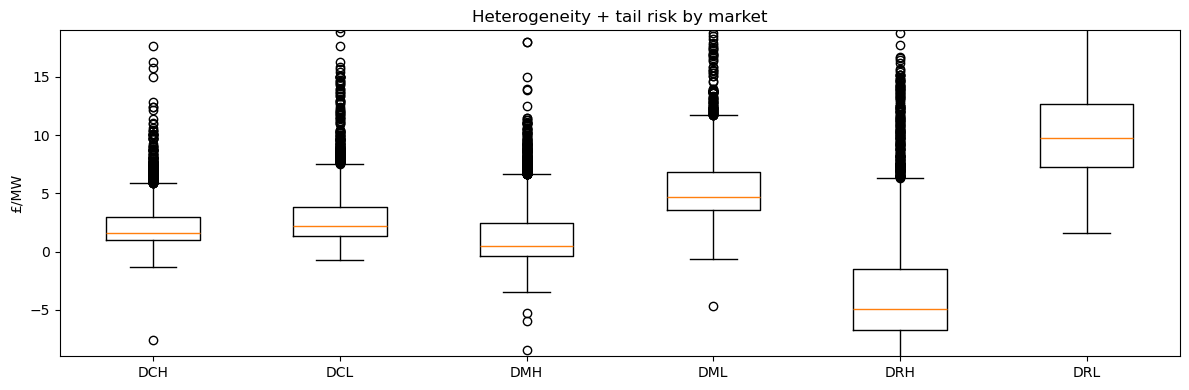

In [ ]:
df = df_prices_volumes.copy()
df["deliveryStart"] = pd.to_datetime(df.index)

prods = sorted(df["auctionProduct"].unique())
vals = [df.loc[df["auctionProduct"]==p, "hourly_price"].dropna().values for p in prods]

plt.figure(figsize=(12,4))
plt.boxplot(vals, labels=prods, showfliers=True)
plt.ylabel("£/MW")
plt.title("Heterogeneity + tail risk by market")

# Clip axis to show the boxes clearly (still keeps outliers plotted)
ymin = df["hourly_price"].quantile(0.01)
ymax = df["hourly_price"].quantile(0.99)
plt.ylim(ymin, ymax)

plt.tight_layout()
plt.show()

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24376\3335406405.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


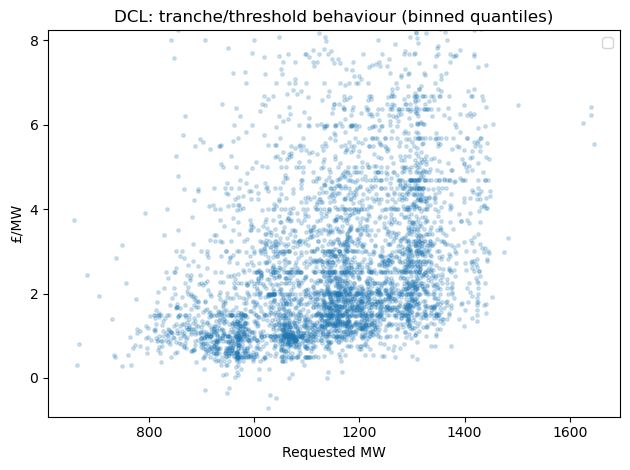

In [ ]:
p = "DCL"  # pick 1 market to keep it clean
d = df[df["auctionProduct"]==p].dropna(subset=["sum_requested_mw","hourly_price"]).copy()

plt.scatter(d["sum_requested_mw"], d["hourly_price"], s=6, alpha=0.2)


plt.xlabel("Requested MW")
plt.ylabel("£/MW")
plt.title(f"{p}: tranche/threshold behaviour (binned quantiles)")
plt.legend()

ymin = df["hourly_price"].quantile(0.15)
ymax = df["hourly_price"].quantile(0.85)
plt.ylim(ymin, ymax)

plt.tight_layout()
plt.show()


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24376\122315696.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  g = d.groupby("mw_bin")


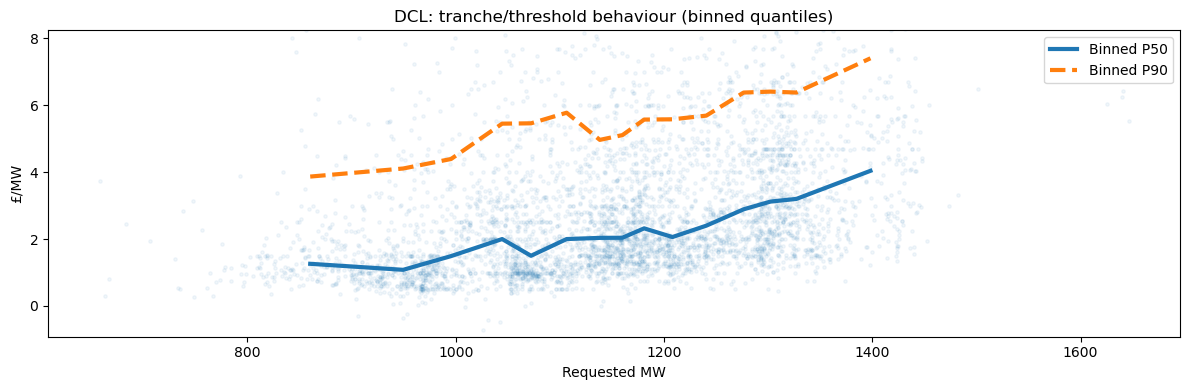

In [ ]:
p = "DCL"  # pick 1 market to keep it clean
d = df[df["auctionProduct"]==p].dropna(subset=["sum_requested_mw","hourly_price"]).copy()

# bins on MW
d["mw_bin"] = pd.qcut(d["sum_requested_mw"], q=15, duplicates="drop")

g = d.groupby("mw_bin")
bin_mid = g["sum_requested_mw"].mean()
p50 = g["hourly_price"].quantile(0.5)
p90 = g["hourly_price"].quantile(0.9)

plt.figure(figsize=(12,4))

# scatter: lighter + smaller so lines pop
plt.scatter(d["sum_requested_mw"], d["hourly_price"], s=6, alpha=0.06)

# binned lines: thick so they are visible
plt.plot(bin_mid.values, p50.values, linewidth=3, label="Binned P50")
plt.plot(bin_mid.values, p90.values, linewidth=3, linestyle="--", label="Binned P90")

plt.xlabel("Requested MW")
plt.ylabel("£/MW")
plt.title(f"{p}: tranche/threshold behaviour (binned quantiles)")
plt.legend()

    
ymin = df["hourly_price"].quantile(0.15)
ymax = df["hourly_price"].quantile(0.85)
plt.ylim(ymin, ymax)

plt.tight_layout()
plt.show()

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24376\3435640420.py:4: FutureWarning: 'Q' is deprecated and will be removed in a future version, please use 'QE' instead.
  monthly = d["hourly_price"].resample("Q").agg(


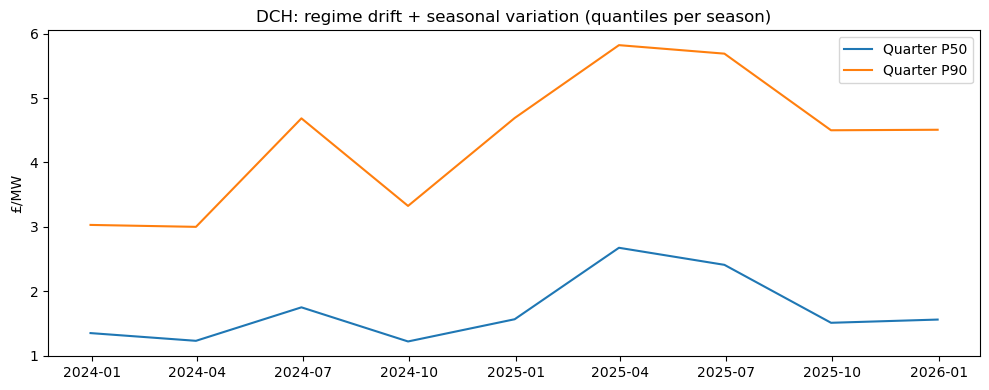

In [ ]:


p = "DCH"
d = df[df["auctionProduct"]==p].set_index("deliveryStart").sort_index()

monthly = d["hourly_price"].resample("Q").agg(
    p50=lambda x: x.quantile(0.5),
    p90=lambda x: x.quantile(0.9),
)

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(monthly.index, monthly["p50"], label="Quarter P50")
ax.plot(monthly.index, monthly["p90"], label="Quarter P90")
ax.set_title(f"{p}: regime drift + seasonal variation (quantiles per season)")
ax.set_ylabel("£/MW")



ax.legend()
plt.tight_layout()
plt.show()

## Data manipulation into panel data

In [23]:
## Look at differences between date ranges in all datasets

min_date = [df_ancillary['deliveryStart'].min()]
max_date = [df_ancillary['deliveryEnd'].max()]

for df_temp in [df_carbon, df_frequency, df_demand, df_pricing]:
    idx = df_temp.index
    min_date.append(idx.min())
    max_date.append(idx.max())
    print(idx)

DatetimeIndex(['2009-01-01 00:00:00', '2009-01-01 00:30:00',
               '2009-01-01 01:00:00', '2009-01-01 01:30:00',
               '2009-01-01 02:00:00', '2009-01-01 02:30:00',
               '2009-01-01 03:00:00', '2009-01-01 03:30:00',
               '2009-01-01 04:00:00', '2009-01-01 04:30:00',
               ...
               '2025-11-25 07:00:00', '2025-11-25 07:30:00',
               '2025-11-25 08:00:00', '2025-11-25 08:30:00',
               '2025-11-25 09:00:00', '2025-11-25 09:30:00',
               '2025-11-25 10:00:00', '2025-11-25 10:30:00',
               '2025-11-25 11:00:00', '2025-11-25 11:30:00'],
              dtype='datetime64[ns]', name='DATETIME', length=296280, freq=None)
DatetimeIndex(['2020-01-01 00:00:00', '2020-01-01 00:30:00',
               '2020-01-01 01:00:00', '2020-01-01 01:30:00',
               '2020-01-01 02:00:00', '2020-01-01 02:30:00',
               '2020-01-01 03:00:00', '2020-01-01 03:30:00',
               '2020-01-01 04:00:00', '2020-0

In [24]:
## Limit datasets to intersection of dates

start = max(min_date)
end = min(max_date)

print(start, end)

df_prices_volumes_ltd = df_prices_volumes[(df_prices_volumes.index >= start) &
                                      (df_prices_volumes.index <= end)]

df_carbon_ltd, df_frequency_ltd, df_demand_ltd, df_pricing_ltd = [
    d.loc[df_prices_volumes_ltd.index.min():df_prices_volumes_ltd.index.max()] for d in (df_carbon, df_frequency, df_demand, df_pricing)
]

df_carbon_ltd, df_frequency_ltd, df_demand_ltd, df_pricing_ltd = [
    d.resample("4h", origin="start").mean() for d in (df_carbon_ltd, df_frequency_ltd, df_demand_ltd, df_pricing_ltd)
]

2024-01-01 00:00:00 2025-11-04 23:30:00


In [25]:
df_model = df_prices_volumes_ltd.join([df_carbon_ltd, df_frequency_ltd, df_demand_ltd, df_pricing_ltd], how="left")
df_model

,auctionProduct,sum_requested_mw,hourly_price,CARBON_INTENSITY,frequency,national_demand,system_price
deliveryStart,,,,,,,
2024-01-01 03:00:00,DCH,1250.0,5.00,62.500,-0.01125,18622.875,102.92125
2024-01-01 07:00:00,DCH,1250.0,2.31,54.375,-0.00625,22529.000,84.25000
2024-01-01 11:00:00,DCH,1160.0,1.25,96.125,-0.02875,28750.125,85.12375
2024-01-01 15:00:00,DCH,997.0,2.21,112.625,0.02375,33560.750,56.69500
2024-01-01 19:00:00,DCH,1087.0,1.10,57.875,0.05375,26959.250,5.06250
...,...,...,...,...,...,...,...
2025-11-04 07:00:00,DRL,480.0,11.72,68.125,-0.01125,29671.500,70.31000
2025-11-04 11:00:00,DRL,480.0,12.85,78.750,-0.02000,30489.875,65.54250
2025-11-04 15:00:00,DRL,480.0,21.57,115.875,-0.00250,34623.625,108.61250


In [26]:
df_model["efa"] = df_model.index.hour.map({23:1,3:2,7:3,11:4,15:5,19:6}).astype("category")

df_model["season"] = df_model.index.month.map({12:"winter",1:"winter",2:"winter",
                                  3:"spring",4:"spring",5:"spring",
                                  6:"summer",7:"summer",8:"summer",
                                  9:"autumn",10:"autumn",11:"autumn"})
df_model["is_weekend"] = (df_model.index.dayofweek >= 5).astype(int)  # Sat/Sun = 1
df_model["is_weekend"] = df_model["is_weekend"].astype("category")

In [27]:
df_model = df_model.sort_values(["auctionProduct", "deliveryStart"]).copy()
g = df_model.groupby("auctionProduct", sort=False)

df_model["lag_1efa"] = g["hourly_price"].shift(1)

# IMPORTANT: if your rows are EFA blocks (6 per day), then lag_6 = "1 day ago"
# If your rows are hourly, use shift(24) for 24h.
df_model["lag_24h"] = g["hourly_price"].shift(6)

df_model["rollmean_24h"] = (
    g["hourly_price"].shift(1).rolling(6, min_periods=6).mean()
)
df_model["rollstd_24h"] = (
    g["hourly_price"].shift(1).rolling(6, min_periods=6).std()
)
df_model["rollmax_24h"] = (
    g["hourly_price"].shift(1).rolling(6, min_periods=6).max()
)

df_model = df_model.dropna(subset=["lag_1efa","lag_24h","rollmean_24h","rollstd_24h","rollmax_24h"])
df_model

,auctionProduct,sum_requested_mw,hourly_price,CARBON_INTENSITY,frequency,national_demand,system_price,efa,season,is_weekend,lag_1efa,lag_24h,rollmean_24h,rollstd_24h,rollmax_24h
deliveryStart,,,,,,,,,,,,,,,
2024-01-02 03:00:00,DCH,1250.0,4.07,64.125,-0.03375,19779.750,-9.69750,2,winter,0,1.40,5.00,2.211667,1.456289,5.00
2024-01-02 07:00:00,DCH,1250.0,1.23,118.625,-0.00500,31516.125,26.92125,3,winter,0,4.07,2.31,2.056667,1.108001,4.07
2024-01-02 11:00:00,DCH,964.0,0.53,151.500,0.00875,35660.250,73.75875,4,winter,0,1.23,1.25,1.876667,1.145699,4.07
2024-01-02 15:00:00,DCH,952.0,1.20,140.625,0.00500,37105.250,99.87500,5,winter,0,0.53,2.21,1.756667,1.256784,4.07
2024-01-02 19:00:00,DCH,1172.0,0.81,98.500,0.00750,30957.500,58.29875,6,winter,0,1.20,1.10,1.588333,1.251550,4.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-11-04 07:00:00,DRL,480.0,11.72,68.125,-0.01125,29671.500,70.31000,3,autumn,0,6.23,15.88,13.480000,6.115371,21.43
2025-11-04 11:00:00,DRL,480.0,12.85,78.750,-0.02000,30489.875,65.54250,4,autumn,0,11.72,11.33,12.786667,6.023988,21.43
2025-11-04 15:00:00,DRL,480.0,21.57,115.875,-0.00250,34623.625,108.61250,5,autumn,0,12.85,21.43,13.040000,5.982294,21.43


### Plots

C:\Users\duval1e\AppData\Local\Temp\ipykernel_10432\2453519255.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)   # hide extreme fliers for readability


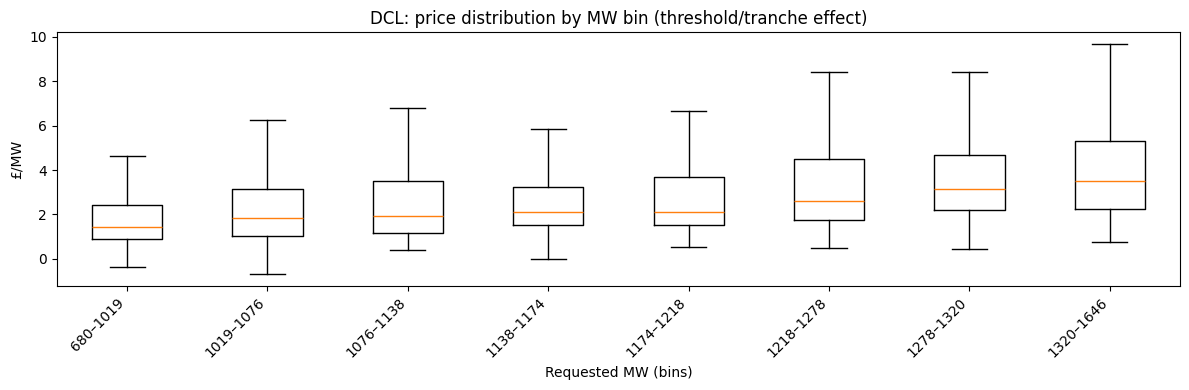

In [28]:
p = "DCL"  # try DCH/DRL too if clearer
d = df_model[df_model["auctionProduct"] == p].dropna(subset=["sum_requested_mw","hourly_price"]).copy()

# MW bins
d["mw_bin"] = pd.qcut(d["sum_requested_mw"], q=8, duplicates="drop")

cats = d["mw_bin"].cat.categories
data = [d.loc[d["mw_bin"] == c, "hourly_price"].values for c in cats]
labels = [f"{int(c.left)}–{int(c.right)}" for c in cats]

plt.figure(figsize=(12,4))
plt.boxplot(data, labels=labels, showfliers=False)   # hide extreme fliers for readability
plt.xticks(rotation=45, ha="right")
plt.xlabel("Requested MW (bins)")
plt.ylabel("£/MW")
plt.title(f"{p}: price distribution by MW bin (threshold/tranche effect)")
plt.tight_layout()
plt.show()


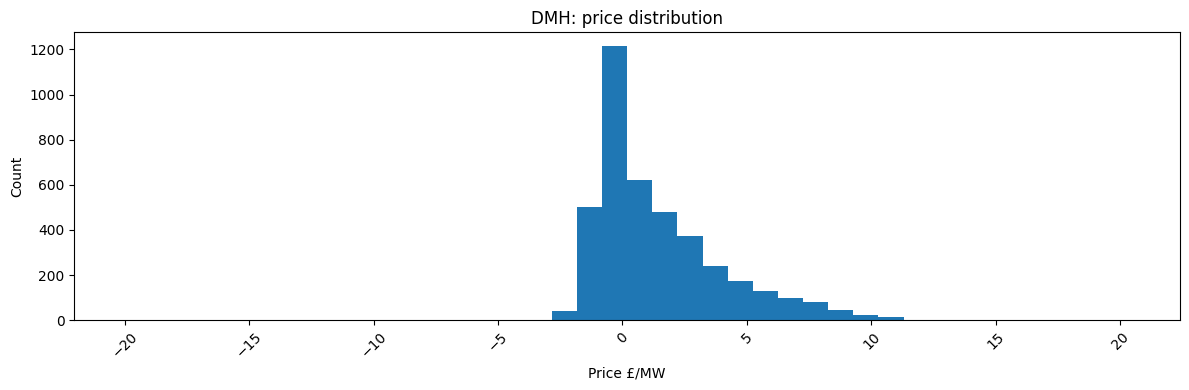

In [29]:
p = "DMH"  # try DCH/DRL too if clearer
d = df_model[df_model["auctionProduct"] == p]["hourly_price"]


plt.figure(figsize=(12,4))
plt.hist(d, bins =40)   # hide extreme fliers for readability
plt.xticks(rotation=45)
plt.xlabel("Price £/MW")
plt.ylabel("Count")
plt.title(f"{p}: price distribution")


plt.tight_layout()
plt.show()

C:\Users\duval1e\AppData\Local\Temp\ipykernel_10432\1271939882.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = d.pivot_table(index="tight_bin", columns="mw_bin", values="hourly_price", aggfunc="median")


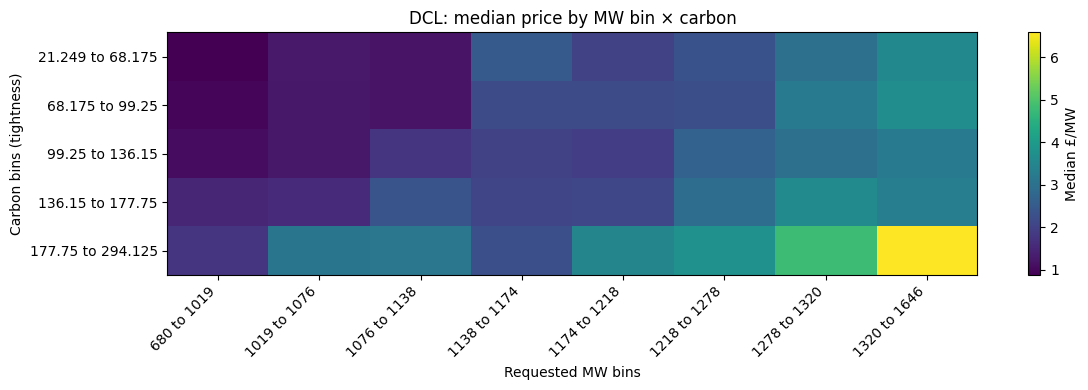

In [30]:
p = "DCL"  # pick 1 market to keep it clean
d = df_model[df_model["auctionProduct"]==p].dropna(subset=["sum_requested_mw","hourly_price"]).copy()

d["mw_bin"] = pd.qcut(d["sum_requested_mw"], q=8, duplicates="drop")
d["tight_bin"] = pd.qcut(d["CARBON_INTENSITY"], q=5, duplicates="drop")  # proxy for tightness

pivot = d.pivot_table(index="tight_bin", columns="mw_bin", values="hourly_price", aggfunc="median")

plt.figure(figsize=(12,4))
plt.imshow(pivot.values, aspect="auto")
plt.colorbar(label="Median £/MW")
plt.title(f"{p}: median price by MW bin × carbon")
plt.xlabel("Requested MW bins")
plt.ylabel("Carbon bins (tightness)")
plt.xticks(range(pivot.shape[1]), [f"{int(c.left)} to {int(c.right)}" for c in pivot.columns], rotation=45, ha="right")
plt.yticks(range(pivot.shape[0]), [f"{round(c.left,4)} to {round(c.right,4)}" for c in pivot.index])
plt.tight_layout()
plt.show()

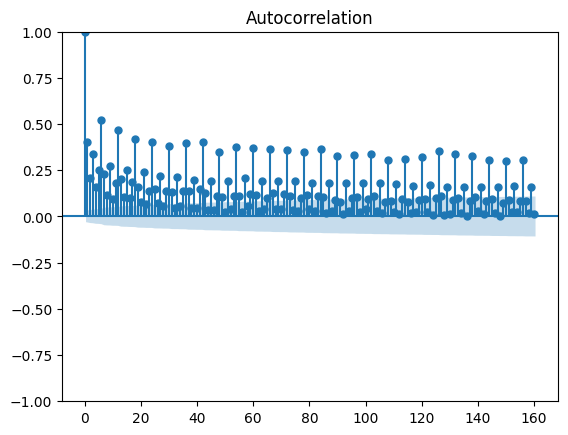

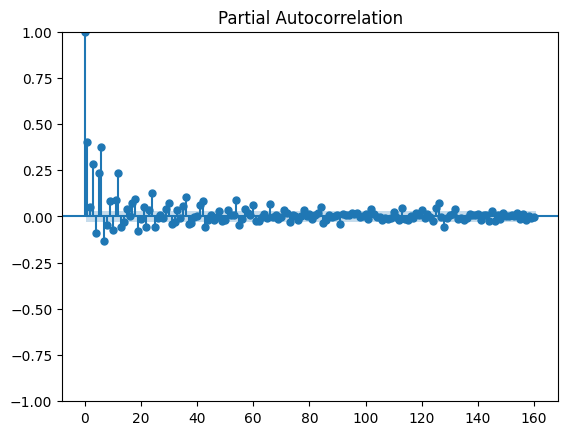

In [31]:
s = (df_model
       .query("auctionProduct == 'DMH'")["hourly_price"]
       .dropna())

fig = plot_acf(s, lags=160)   # ~8 days
plt.show()

fig = plot_pacf(s, lags=160, method="ywm")
plt.show()

# Lag 1 is high (~0.4–0.5) → strong persistence from the previous EFA block.

# There’s a very clear repeating “wave” with big spikes around lag 6, 12, 18, …
# That’s daily seasonality

# ACF (autocorrelation function) is a way to answer:

# “Does the value now look like the value from a little while ago?”

# The vertical lines are “memory strength” at different time gaps.

# A tall line at lag 
# 𝑘
# k means: “If I know the price 
# 𝑘
# k steps ago, I get a useful hint about today’s price.”

# Lines near zero mean: “Knowing the value 
# 𝑘
# k steps ago doesn’t really help.”

# The shaded band is basically “what you might see by luck if there was no real pattern.”
# If a line sticks out past that band, it’s probably a real pattern, not noise.

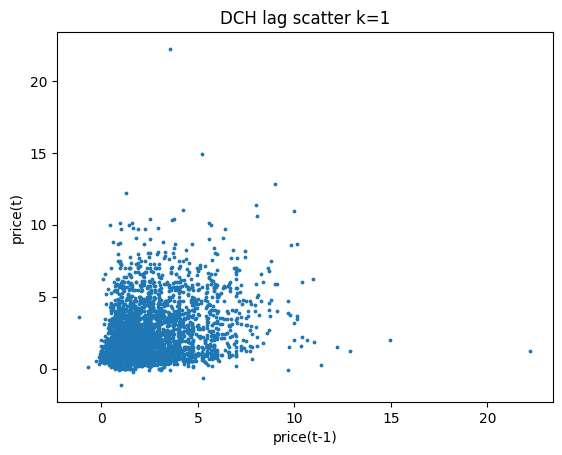

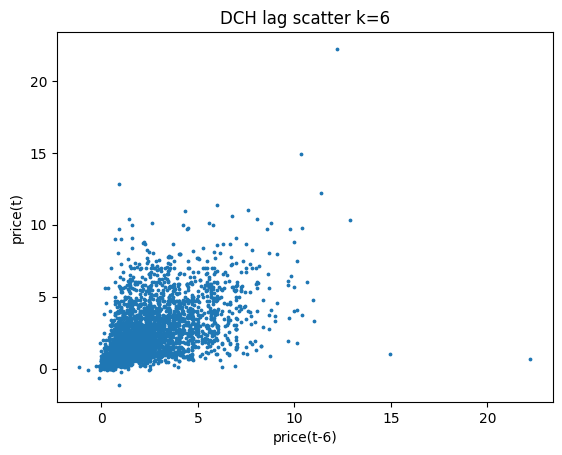

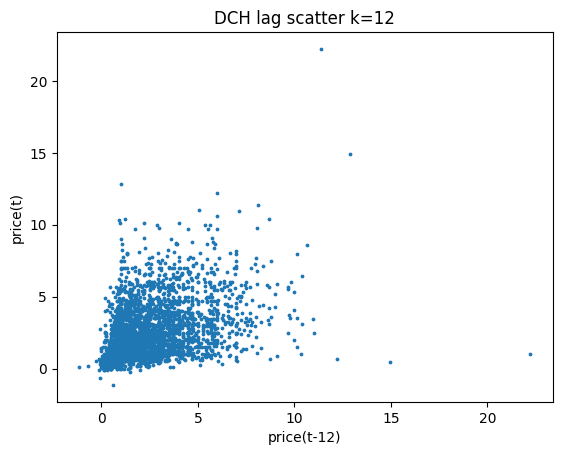

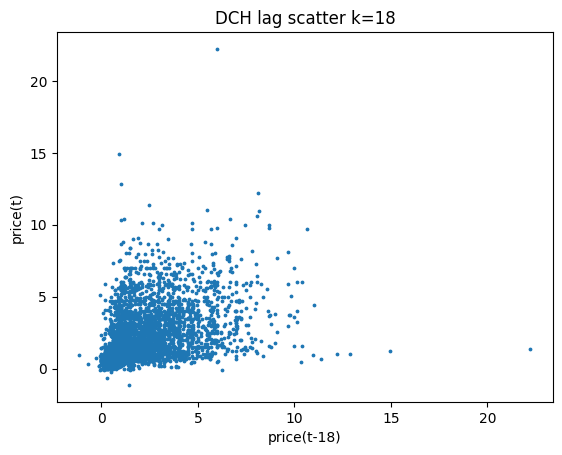

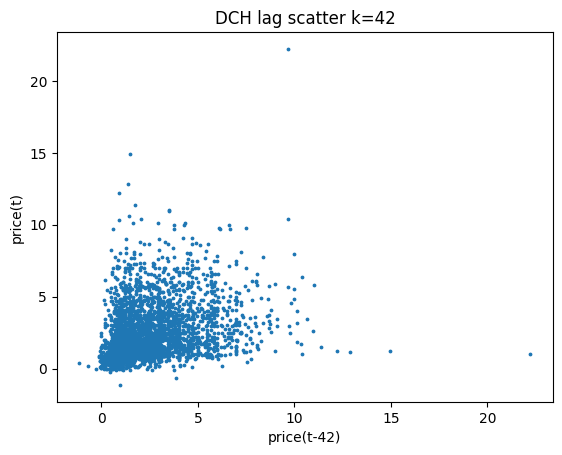

In [32]:
d = (df_model[df_model["auctionProduct"]=="DCH"])

for k in [1, 6, 6*2, 6*3, 42]:
    x = d["hourly_price"].shift(k)
    y = d["hourly_price"]
    m = x.notna() & y.notna()
    plt.figure()
    plt.scatter(x[m], y[m], s=3)
    plt.xlabel(f"price(t-{k})")
    plt.ylabel("price(t)")
    plt.title(f"DCH lag scatter k={k}")
    plt.show()

## Model 

In [33]:


# train_end = "2024-12-31"
# valid_end = "2025-09-30"

# train = df_model[(df_model.index <= train_end)]
# valid = df_model[(df_model.index > train_end) &
#                                       (df_model.index <= valid_end)]
# test  = df_model[(df_model.index > valid_end)]

train_end = "2025-07-30"

train = df_model[(df_model.index <= train_end)]
test  = df_model[(df_model.index > train_end)]


panel = make_X(train.reset_index().set_index(["auctionProduct", "deliveryStart"]).sort_index())
test_panel = make_X(test.reset_index().set_index(["auctionProduct", "deliveryStart"]).sort_index())

### SMF OLS

In [336]:
cont = ["frequency","CARBON_INTENSITY","system_price", 'lag_1efa', 'lag_24h', 'rollmean_24h',
       'rollstd_24h', 'rollmax_24h']
train[cont] = (train[cont] - train[cont].mean()) / train[cont].std()

formula = """ hourly_price ~ auctionProduct + frequency + sum_requested_mw + efa + season + is_weekend +lag_1efa + lag_24h + rollmean_24h + rollstd_24h + rollmax_24h """

#+ CARBON_INTENSITY + system_price

model = smf.ols(formula, data=train).fit(cov_type="HAC", cov_kwds={"maxlags": 24})
print(model.summary())

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\2765368294.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train[cont] = (train[cont] - train[cont].mean()) / train[cont].std()


                            OLS Regression Results                            
Dep. Variable:           hourly_price   R-squared:                       0.767
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     2731.
Date:                Thu, 04 Dec 2025   Prob (F-statistic):               0.00
Time:                        20:27:09   Log-Likelihood:                -49307.
No. Observations:               20682   AIC:                         9.866e+04
Df Residuals:                   20660   BIC:                         9.883e+04
Df Model:                          21                                         
Covariance Type:                  HAC                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 2.63

In [79]:
### no intercations -- simplest

train = train.copy()

train["mw_bin"], mw_edges = pd.qcut(train["sum_requested_mw"],
                                    q=5, retbins=True, duplicates="drop")

# (optional) z-score continuous vars you actually use
cont = ["frequency","CARBON_INTENSITY","system_price"]
train[cont] = (train[cont] - train[cont].mean()) / train[cont].std()

formula = """
hourly_price ~ C(auctionProduct)
           + C(mw_bin)
           + C(efa) + C(season) + C(is_weekend)
           + frequency + CARBON_INTENSITY + system_price
"""

model = smf.ols(formula, data=train).fit(cov_type="HAC", cov_kwds={"maxlags": 24})
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           hourly_price   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     231.6
Date:                Thu, 04 Dec 2025   Prob (F-statistic):               0.00
Time:                        10:36:25   Log-Likelihood:                -54843.
No. Observations:               20718   AIC:                         1.097e+05
Df Residuals:                   20696   BIC:                         1.099e+05
Df Model:                          21                                         
Covariance Type:                  HAC                                         
                                                            coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------

In [337]:
# mw_edges[0]  = -np.inf
# mw_edges[-1] =  np.inf

# test["mw_bin"] = pd.cut(test["sum_requested_mw"], bins=mw_edges, include_lowest=True)

test[cont] = (test[cont] - test[cont].mean()) / test[cont].std()

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\763296148.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test[cont] = (test[cont] - test[cont].mean()) / test[cont].std()


In [338]:
# pred_val = model.predict(valid.reset_index(drop=True))
pred_test  = model.predict(test.reset_index(drop=True))

# pred_val.index = valid.index
pred_test.index = test.index

# valid['hourly_price'] = np.exp(valid['hourly_price'])
# test['hourly_price']  = np.exp(test['hourly_price'])

In [340]:
test['hourly_price'].describe()

count    3528.000000
mean        4.605057
std         6.265097
min        -9.190000
25%         1.077500
50%         3.485000
75%         7.470000
max        49.750000
Name: hourly_price, dtype: float64

In [ ]:


# mae_v, rmse_v, mape_v = eval_forecast(valid['hourly_price'][pred_val.index.notna()], pred_val.dropna())
mae_t, rmse_t, mape_t = eval_forecast(test['hourly_price'],  pred_test)

# print("Validation - MAE:", mae_v, "RMSE:", rmse_v, "MAPE:", mape_v)
print("Test       - MAE:", mae_t, "RMSE:", rmse_t, "MAPE:", mape_t)

## - 1 efa at 2.7
## lags - 0.4 at 2.3

Test       - MAE: 2.377160012849286 RMSE: 3.543302127074572 MAPE: inf


count    588.000000
mean       2.194575
std        1.625325
min       -0.010000
25%        1.000000
50%        1.640000
75%        2.982500
max       11.000000
Name: hourly_price, dtype: float64
Test       - MAE: 1.359577944168669 RMSE: 1.8501976664458002 MAPE: inf


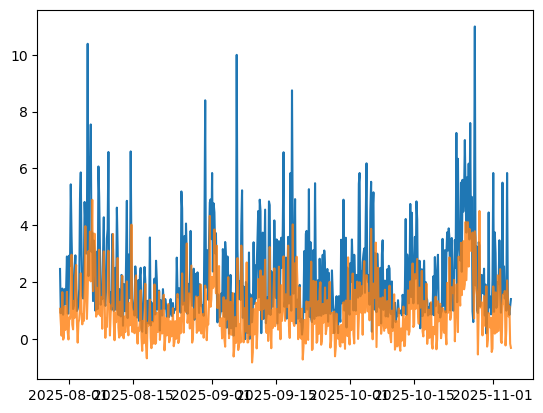

count    588.00000
mean       3.89966
std        2.60056
min        0.15000
25%        2.03500
50%        3.13000
75%        5.08250
max       19.18000
Name: hourly_price, dtype: float64
Test       - MAE: 1.815132755331413 RMSE: 2.6823122161880253 MAPE: 44.54046930180949


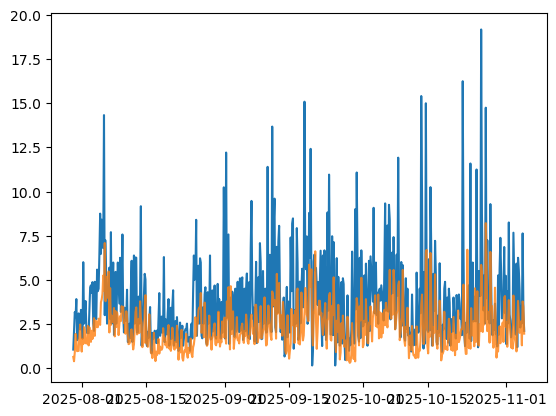

count    588.000000
mean       2.354167
std        2.593550
min       -1.200000
25%        0.300000
50%        1.670000
75%        3.482500
max       11.290000
Name: hourly_price, dtype: float64
Test       - MAE: 1.7420404121696302 RMSE: 2.4334529662689595 MAPE: inf


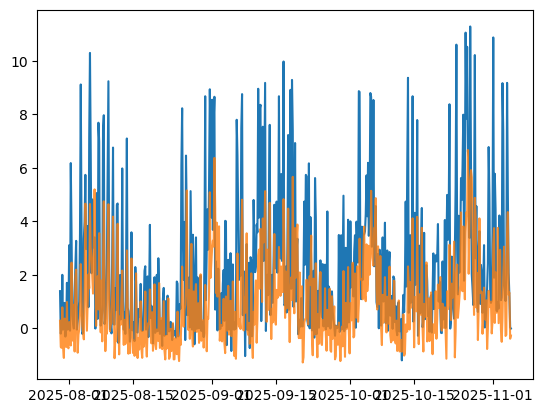

count    588.000000
mean       6.809031
std        3.213027
min        1.750000
25%        4.467500
50%        5.870000
75%        8.382500
max       22.870000
Name: hourly_price, dtype: float64
Test       - MAE: 2.441616365703116 RMSE: 3.4142762016515014 MAPE: 31.109396611515105


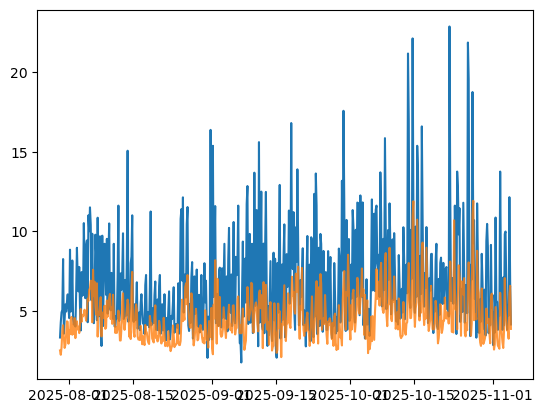

count    588.000000
mean      -1.640969
std        5.638077
min       -9.190000
25%       -5.695000
50%       -3.400000
75%        0.727500
max       20.330000
Name: hourly_price, dtype: float64
Test       - MAE: 2.9054592472253855 RMSE: 4.215621459524118 MAPE: 243.10629585885172


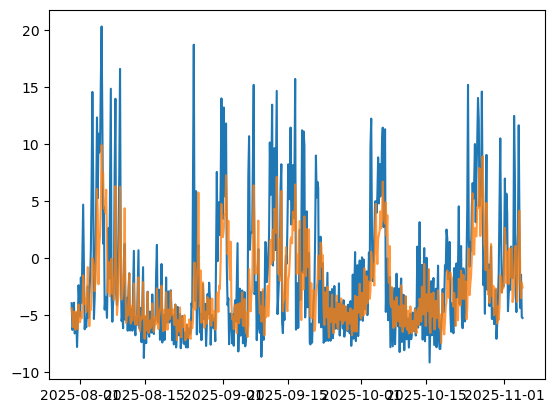

count    588.000000
mean      14.013878
std        5.795237
min        2.530000
25%       10.120000
50%       13.335000
75%       17.000000
max       49.750000
Name: hourly_price, dtype: float64
Test       - MAE: 3.9991333524974997 RMSE: 5.418622513346621 MAPE: 28.308024408457417


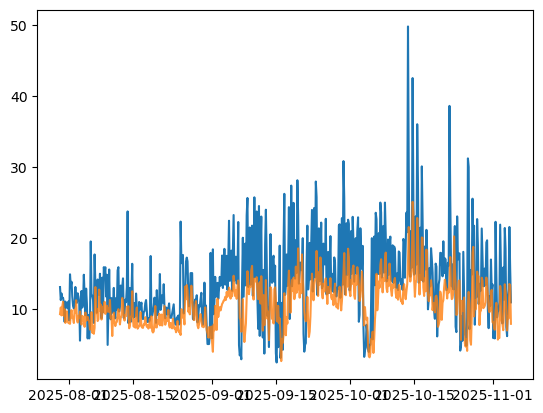

In [341]:

start, end = 0, int(np.shape(test)[0]/6)

for i in range(6):
    range_start = int(np.shape(test)[0]/6)*i
    range_end = int(np.shape(test)[0]/6)*(i+1)
    plt.plot(test.iloc[range_start:range_end]['hourly_price'])
    print(test.iloc[range_start:range_end]['hourly_price'].describe())
    mae_t, rmse_t, mape_t = eval_forecast(test.iloc[range_start:range_end]['hourly_price'],  pred_test.iloc[range_start:range_end])

# print("Validation - MAE:", mae_v, "RMSE:", rmse_v, "MAPE:", mape_v)
    print("Test       - MAE:", mae_t, "RMSE:", rmse_t, "MAPE:", mape_t)
    plt.plot(pred_test.iloc[range_start:range_end], alpha=0.8)
    plt.show()

### Hubert

Test       - MAE: 2.420195871847793 RMSE: 3.6048588887166773 MAPE: inf
(1.4186960212822117, 1.8930468487572103, inf)


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\338728343.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100
C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\338728343.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


<Figure size 640x480 with 0 Axes>

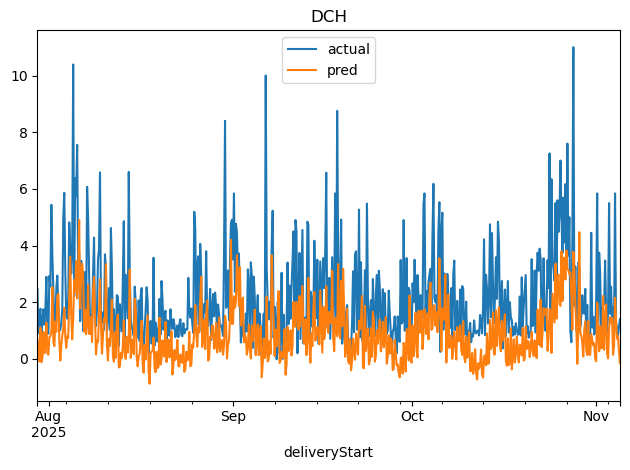

(1.8753524345848978, 2.713074620246193, 47.004112746158)


<Figure size 640x480 with 0 Axes>

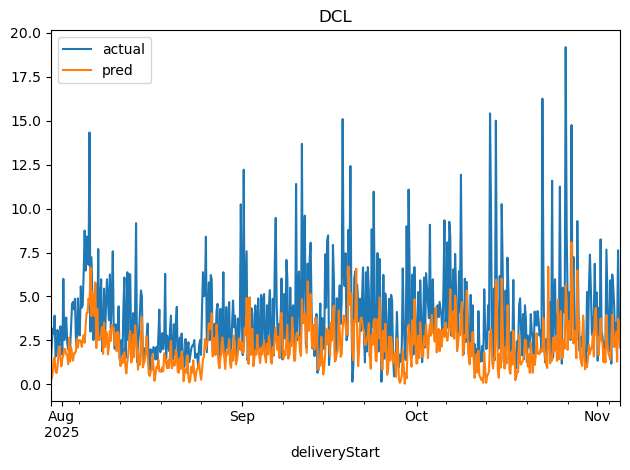

(1.7300902622339713, 2.438844965104444, inf)


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\338728343.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


<Figure size 640x480 with 0 Axes>

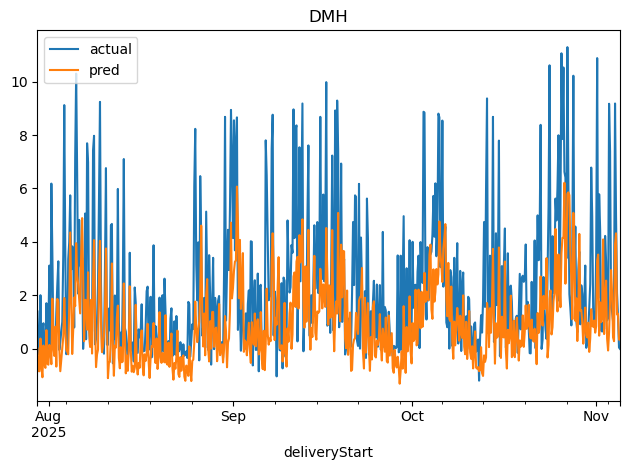

(2.3111397144856913, 3.2801983806585886, 29.46495186096031)


<Figure size 640x480 with 0 Axes>

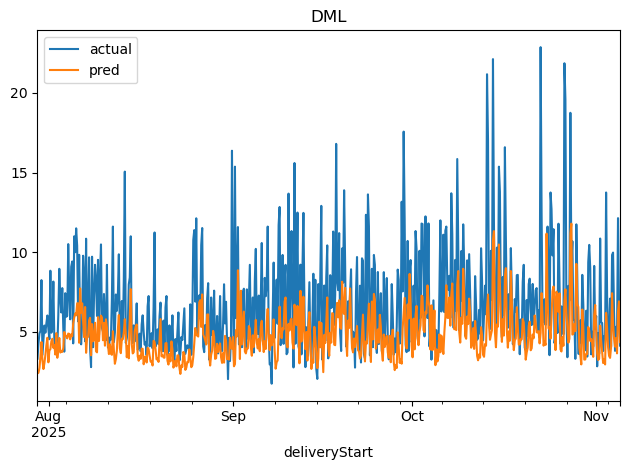

(3.0280251759995034, 4.4209834816872435, 257.85659853912836)


<Figure size 640x480 with 0 Axes>

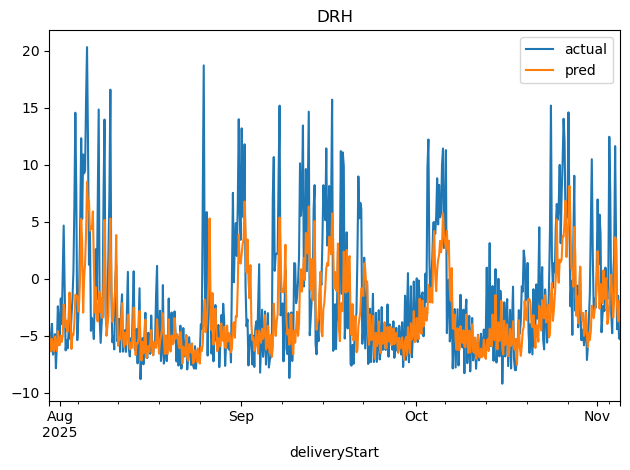

(4.157871622500483, 5.547331273062952, 29.438683404337745)


<Figure size 640x480 with 0 Axes>

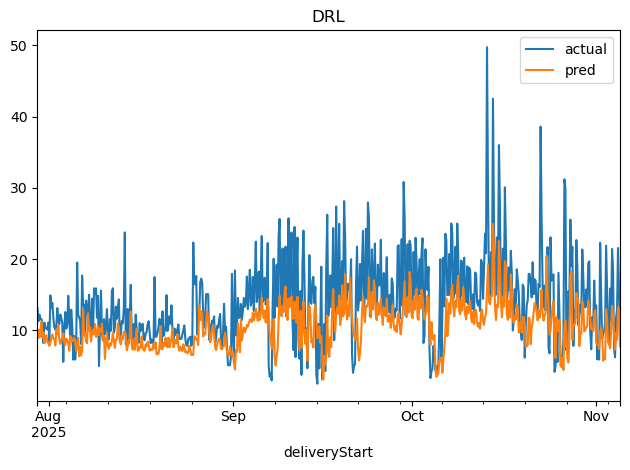

In [318]:
from sklearn.linear_model import HuberRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

cat = ["auctionProduct","efa","season","is_weekend"]
num = ["sum_requested_mw","CARBON_INTENSITY","frequency","national_demand","system_price",
       'lag_1efa', 'lag_24h', 'rollmean_24h',
       'rollstd_24h', 'rollmax_24h']  

X = train[cat + num]
y = train["hourly_price"]

X_test = test[cat + num]

pre = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", Pipeline([("scaler", StandardScaler())]), num),
    ]
)

huber = HuberRegressor(
    epsilon=1.35,     # bigger => less aggressive outlier downweighting
    alpha=0.0001,     # L2 regularization strength
    max_iter=2000
)

model = Pipeline([("pre", pre), ("reg", huber)])

model.fit(X, y)

pred_test  = model.predict(X_test)

# pred_val.index = valid.index
pred_test = pd.DataFrame(data = pred_test, index = test_panel.index)


mae_t, rmse_t, mape_t = eval_forecast(test_panel['hourly_price'].values,  pred_test.values)

print("Test       - MAE:", mae_t, "RMSE:", rmse_t, "MAPE:", mape_t)

actual = test_panel["hourly_price"]   # Series with MultiIndex
pred = pred_test                      # from res.predict(...)

for prod in actual.index.get_level_values("auctionProduct").unique():
    a = actual.xs(prod, level="auctionProduct")

    p = pred.xs(prod, level="auctionProduct")
    # make p 1D
    if isinstance(p, pd.DataFrame):
        p = p.iloc[:, 0]
    else:
        p = pd.Series(p).squeeze()

    df_plot = pd.concat([a.rename("actual"), p.rename("pred")], axis=1)
    
    print(eval_forecast(a.values, p.values))

    plt.figure()
    df_plot.plot()
    plt.title(prod)
    plt.tight_layout()
    plt.show()

### PanelOLS

In [ ]:

y = panel["hourly_price"]
x = panel.drop(columns="hourly_price")

mod = PanelOLS(y, x, entity_effects=True)
# res = mod.fit(cov_type="driscoll-kraay")  # or clustered with cluster_time=True
res = mod.fit(cov_type="clustered", cluster_time=True)

print(res.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:           hourly_price   R-squared:                        0.4592
Estimator:                   PanelOLS   R-squared (Between):              0.9419
No. Observations:               20682   R-squared (Within):               0.4592
Date:                Fri, Dec 05 2025   R-squared (Overall):              0.7830
Time:                        11:54:42   Log-likelihood                -4.919e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      923.07
Entities:                           6   P-value                           0.0000
Avg Obs:                       3447.0   Distribution:                F(19,20657)
Min Obs:                       3433.0                                           
Max Obs:                       3450.0   F-statistic (robust):             286.19
                            

In [279]:
pred_test  = res.predict(test_panel.reindex(columns=x.columns, fill_value=0))

# pred_val.index = valid.index
pred_test.index = test_panel.index

In [280]:
pred_test.index.names = test_panel.index.names

mae_t, rmse_t, mape_t = eval_forecast(test_panel['hourly_price'].values,  pred_test.values)

print("Test       - MAE:", mae_t, "RMSE:", rmse_t, "MAPE:", mape_t)


Test       - MAE: 5.275443137119267 RMSE: 6.076000337968978 MAPE: inf


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\338728343.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


In [205]:
test_panel['hourly_price']

auctionProduct  deliveryStart      
DCH             2025-07-30 03:00:00     2.46
                2025-07-30 07:00:00     0.90
                2025-07-30 11:00:00     1.59
                2025-07-30 15:00:00     1.77
                2025-07-30 19:00:00     0.85
                                       ...  
DRL             2025-11-04 07:00:00    11.72
                2025-11-04 11:00:00    12.85
                2025-11-04 15:00:00    21.57
                2025-11-04 19:00:00    15.76
                2025-11-04 23:00:00    10.98
Name: hourly_price, Length: 3528, dtype: float64

<Figure size 640x480 with 0 Axes>

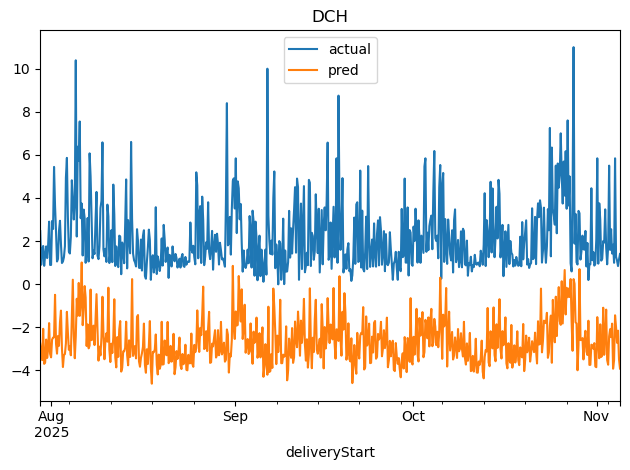

<Figure size 640x480 with 0 Axes>

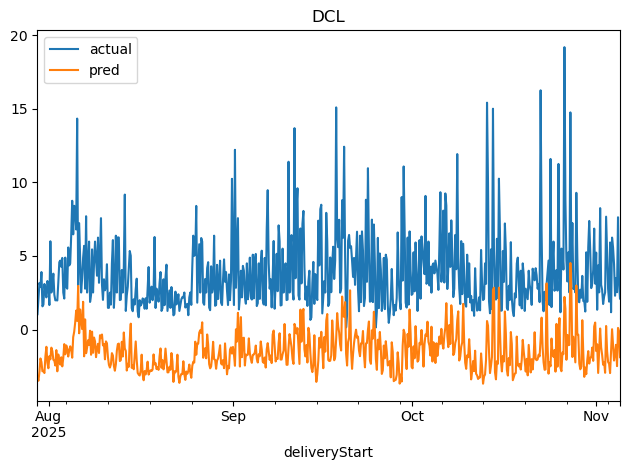

<Figure size 640x480 with 0 Axes>

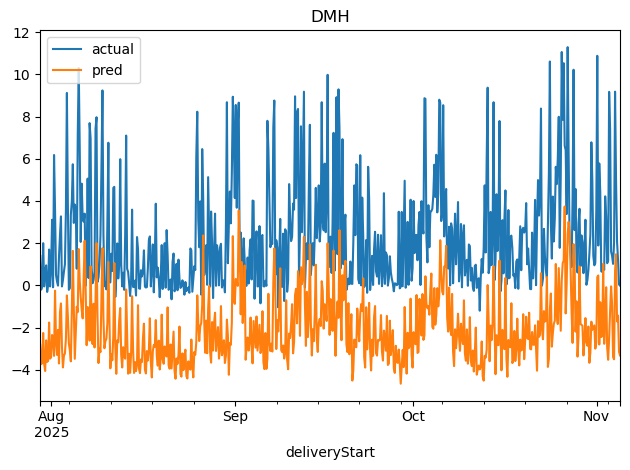

<Figure size 640x480 with 0 Axes>

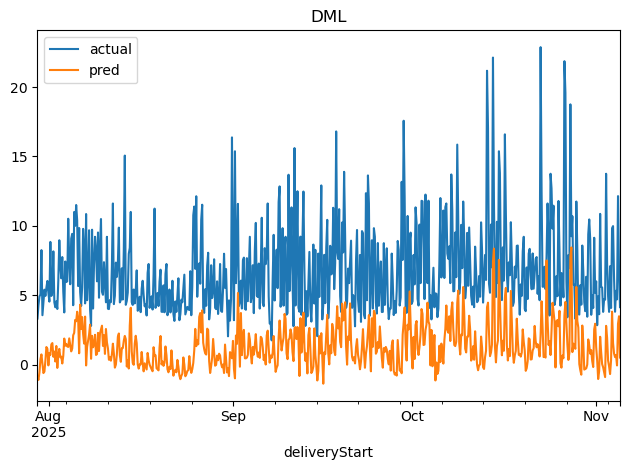

<Figure size 640x480 with 0 Axes>

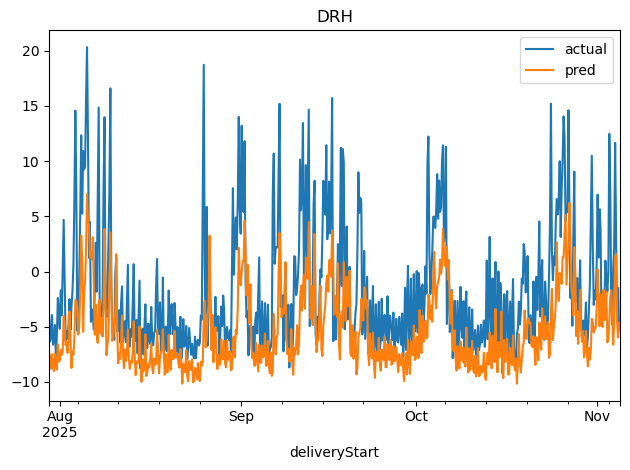

<Figure size 640x480 with 0 Axes>

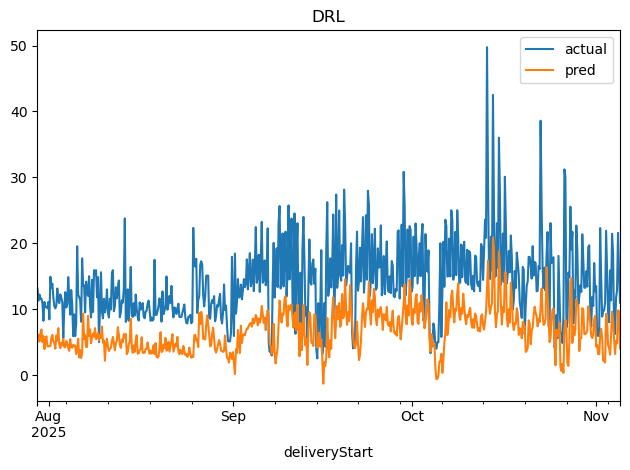

In [281]:
actual = test_panel["hourly_price"]   # Series with MultiIndex
pred = pred_test                      # from res.predict(...)

for prod in actual.index.get_level_values("auctionProduct").unique():
    a = actual.xs(prod, level="auctionProduct")

    p = pred.xs(prod, level="auctionProduct")
    # make p 1D
    if isinstance(p, pd.DataFrame):
        p = p.iloc[:, 0]
    else:
        p = pd.Series(p).squeeze()

    df_plot = pd.concat([a.rename("actual"), p.rename("pred")], axis=1)

    plt.figure()
    df_plot.plot()
    plt.title(prod)
    plt.tight_layout()
    plt.show()



### ML model 


In [37]:
# HistGradientBoostingRegressor
target = "hourly_price"

cat = ["auctionProduct","efa","season","is_weekend"]
num = ["sum_requested_mw","CARBON_INTENSITY","frequency","national_demand","system_price",
       'lag_1efa', 'lag_24h', 'rollmean_24h',
       'rollstd_24h', 'rollmax_24h']  

df = train.dropna(subset=[target] + [c for c in num if c in train.columns])  # drop rows where lags are missing

X = df[cat + [c for c in num if c in df.columns]]
y = df[target]

pre = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", "passthrough", [c for c in num if c in df.columns]),
    ],
    remainder="drop",
)

model = Pipeline([
    ("pre", pre),
    ("gbm", HistGradientBoostingRegressor(loss="absolute_error"))  # robust to spikes vs squared loss
])

tscv = TimeSeriesSplit(n_splits=5)
for i, (tr, te) in enumerate(tscv.split(X), 1):
    model.fit(X.iloc[tr], y.iloc[tr])
    pred = model.predict(X.iloc[te])
    print(i, mean_absolute_error(y.iloc[te], pred))

1 1.5128937718804494
2 1.580162509902218
3 2.298535465330707
4 5.1113789288825195
5 3.492732074857419


0:	learn: 3.7475123	total: 69.6ms	remaining: 5m 47s
200:	learn: 1.2443669	total: 13.4s	remaining: 5m 19s
400:	learn: 1.1130569	total: 25.7s	remaining: 4m 54s
600:	learn: 1.0209410	total: 38.3s	remaining: 4m 40s
800:	learn: 0.9632412	total: 51s	remaining: 4m 27s
1000:	learn: 0.9138454	total: 1m 3s	remaining: 4m 13s
1200:	learn: 0.8780261	total: 1m 15s	remaining: 3m 59s
1400:	learn: 0.8465957	total: 1m 28s	remaining: 3m 46s
1600:	learn: 0.8239603	total: 1m 40s	remaining: 3m 33s
1800:	learn: 0.8048877	total: 1m 53s	remaining: 3m 21s
2000:	learn: 0.7879774	total: 2m 5s	remaining: 3m 8s
2200:	learn: 0.7693886	total: 2m 17s	remaining: 2m 55s
2400:	learn: 0.7550263	total: 2m 30s	remaining: 2m 42s
2600:	learn: 0.7424180	total: 2m 42s	remaining: 2m 30s
2800:	learn: 0.7315116	total: 2m 55s	remaining: 2m 17s
3000:	learn: 0.7195910	total: 3m 7s	remaining: 2m 4s
3200:	learn: 0.7098420	total: 3m 19s	remaining: 1m 52s
3400:	learn: 0.6992685	total: 3m 31s	remaining: 1m 39s
3600:	learn: 0.6883813	total

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\338728343.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100
C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\338728343.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


<Figure size 640x480 with 0 Axes>

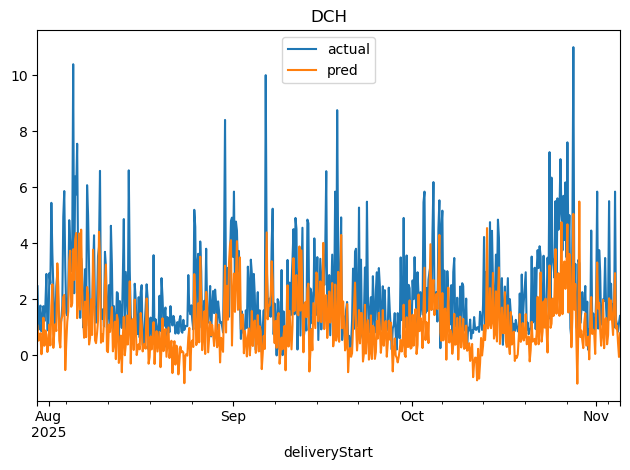

(1.6677191621650933, 2.4002782816210777, 41.63851006325168)


<Figure size 640x480 with 0 Axes>

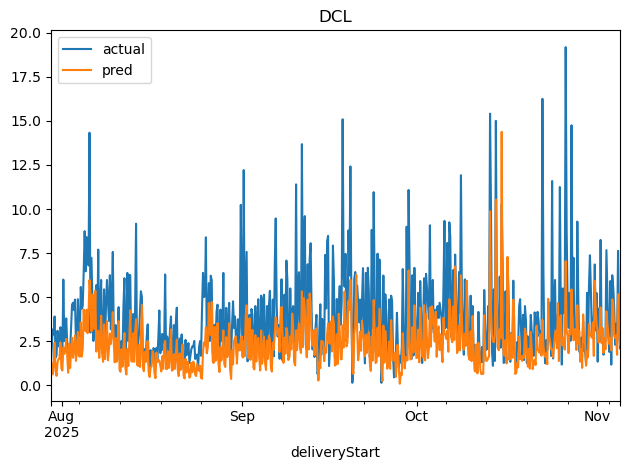

(1.6735394865963218, 2.1811131376250934, inf)


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\338728343.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


<Figure size 640x480 with 0 Axes>

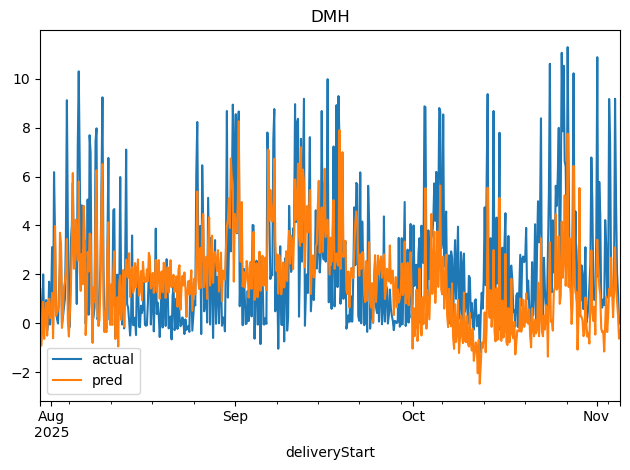

(1.7613858436124823, 2.5429591486820895, 24.902417021222835)


<Figure size 640x480 with 0 Axes>

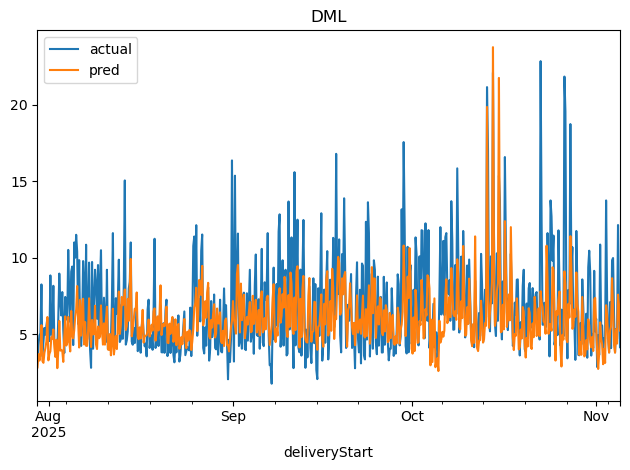

(1.8246765520285166, 2.6946413295878937, 117.94991467974563)


<Figure size 640x480 with 0 Axes>

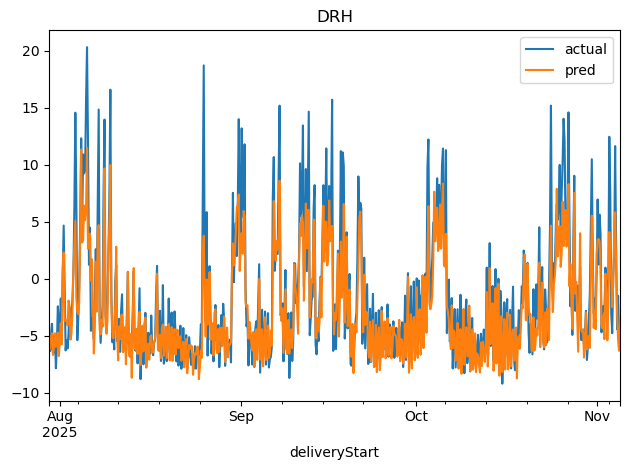

(3.653937983992712, 4.948834902334371, 24.848690720436668)


<Figure size 640x480 with 0 Axes>

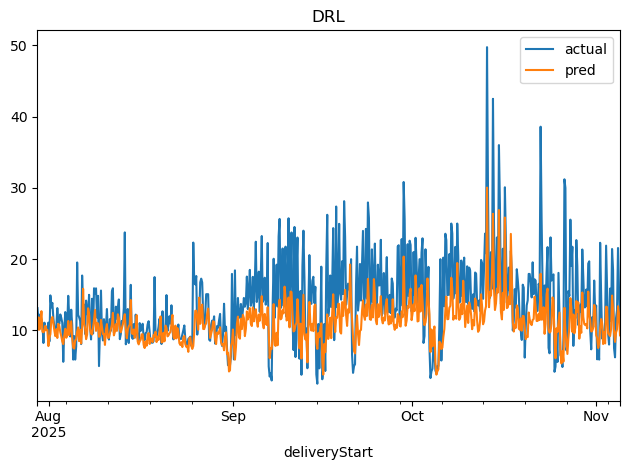

In [ ]:
# CatBoostRegressor
cat_cols = ["auctionProduct", "efa", "season", "is_weekend"]
num_cols = ["sum_requested_mw","CARBON_INTENSITY","frequency","national_demand","system_price",
       'lag_1efa', 'lag_24h', 'rollmean_24h',
       'rollstd_24h', 'rollmax_24h']

X_train = train[cat_cols + num_cols]
y_train = train["hourly_price"]
X_test  = test[cat_cols + num_cols]

model = CatBoostRegressor(
    loss_function="MAE",
    iterations=5000,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=10,
    min_data_in_leaf=100,
    bootstrap_type="Bernoulli",
    subsample=0.8,
    random_strength=1.0,
    od_type="Iter",
    od_wait=200,
    random_seed=42,
    verbose=200
)


model.fit(X_train, y_train, cat_features=cat_cols)

pred_test  = model.predict(X_test)

# pred_val.index = valid.index
pred_test = pd.DataFrame(data = pred_test, index = test_panel.index)


mae_t, rmse_t, mape_t = eval_forecast(test_panel['hourly_price'].values,  pred_test.values)

print("Test       - MAE:", mae_t, "RMSE:", rmse_t, "MAPE:", mape_t)

actual = test_panel["hourly_price"]   # Series with MultiIndex
pred = pred_test                      # from res.predict(...)

for prod in actual.index.get_level_values("auctionProduct").unique():
    a = actual.xs(prod, level="auctionProduct")

    p = pred.xs(prod, level="auctionProduct")
    # make p 1D
    if isinstance(p, pd.DataFrame):
        p = p.iloc[:, 0]
    else:
        p = pd.Series(p).squeeze()

    df_plot = pd.concat([a.rename("actual"), p.rename("pred")], axis=1)
    
    print(eval_forecast(a.values, p.values))

    plt.figure()
    df_plot.plot()
    plt.title(prod)
    plt.tight_layout()
    plt.show()

0:	learn: 1.8725908	total: 74.2ms	remaining: 7m 24s
200:	learn: 0.6501776	total: 12.8s	remaining: 6m 9s
400:	learn: 0.5887000	total: 25s	remaining: 5m 49s
600:	learn: 0.5527222	total: 37.5s	remaining: 5m 37s
800:	learn: 0.5256427	total: 50.1s	remaining: 5m 25s
1000:	learn: 0.5051565	total: 1m 3s	remaining: 5m 19s
1200:	learn: 0.4866615	total: 1m 17s	remaining: 5m 9s
1400:	learn: 0.4716396	total: 1m 30s	remaining: 4m 57s
1600:	learn: 0.4576558	total: 1m 42s	remaining: 4m 41s
1800:	learn: 0.4453806	total: 1m 54s	remaining: 4m 27s
2000:	learn: 0.4341676	total: 2m 6s	remaining: 4m 12s
2200:	learn: 0.4242982	total: 2m 18s	remaining: 3m 58s
2400:	learn: 0.4149275	total: 2m 29s	remaining: 3m 44s
2600:	learn: 0.4062655	total: 2m 41s	remaining: 3m 30s
2800:	learn: 0.3982124	total: 2m 52s	remaining: 3m 17s
3000:	learn: 0.3903313	total: 3m 4s	remaining: 3m 4s
3200:	learn: 0.3833341	total: 3m 16s	remaining: 2m 51s
3400:	learn: 0.3763484	total: 3m 28s	remaining: 2m 39s
3600:	learn: 0.3705045	total:

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\3374769127.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100
C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\3374769127.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


<Figure size 640x480 with 0 Axes>

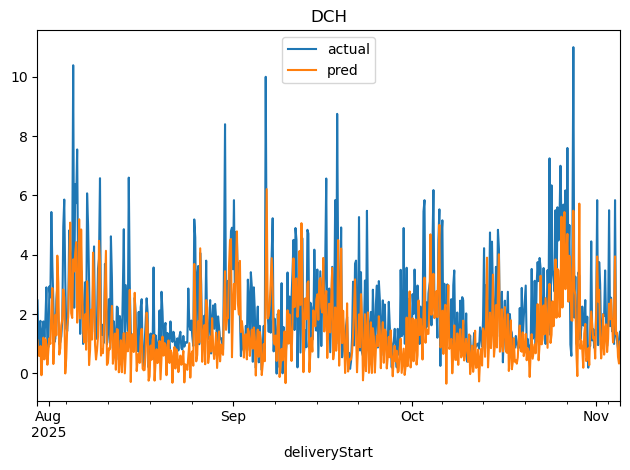

(1.5586633238397927, 2.2818955929080977, 39.12855073504941)


<Figure size 640x480 with 0 Axes>

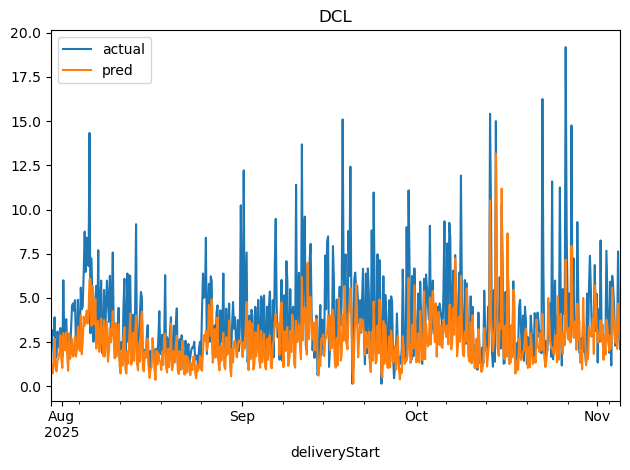

(1.3991578193097711, 1.965073950837854, inf)


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\3374769127.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


<Figure size 640x480 with 0 Axes>

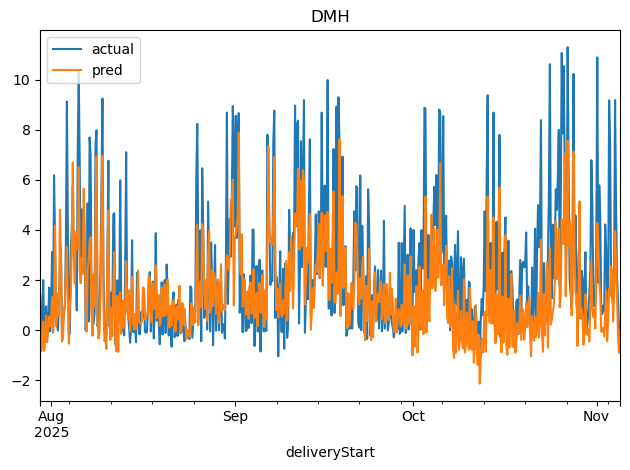

(1.7633849943862194, 2.5630423581971287, 24.096732564423938)


<Figure size 640x480 with 0 Axes>

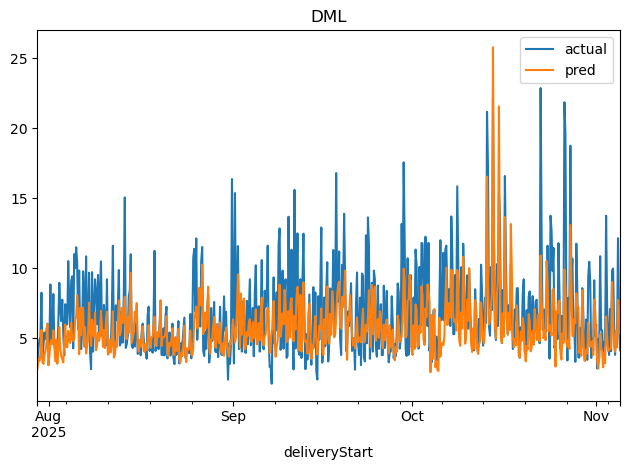

(1.8626748287348802, 2.741460490301608, 101.16127054127577)


<Figure size 640x480 with 0 Axes>

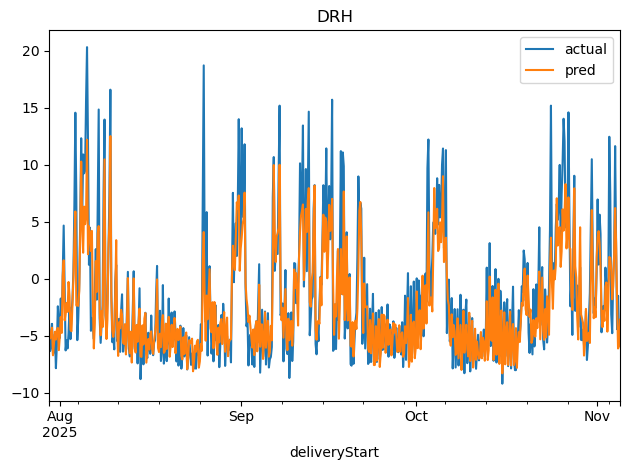

(3.669810499980856, 4.965650790234758, 25.65711627192841)


<Figure size 640x480 with 0 Axes>

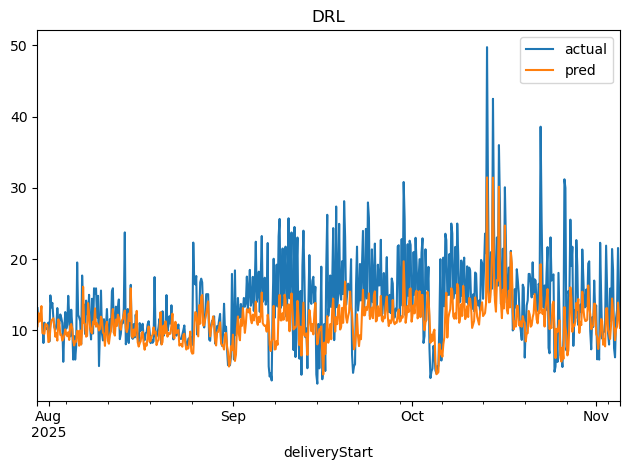

In [ ]:

cat_cols = ["auctionProduct", "efa", "season", "is_weekend"]
num_cols = ["sum_requested_mw","CARBON_INTENSITY","frequency","national_demand","system_price",
       'lag_1efa', 'lag_24h', 'rollmean_24h',
       'rollstd_24h', 'rollmax_24h']

X_train = train[cat_cols + num_cols]
y_train = train["hourly_price"]
X_test  = test[cat_cols + num_cols]

model = CatBoostRegressor(
    loss_function="Quantile:alpha=0.6",
    iterations=6000,
    learning_rate=0.02,
    depth=8,
    l2_leaf_reg=15,
    min_data_in_leaf=150,
    bootstrap_type="Bayesian",
    bagging_temperature=2.0,
    od_type="Iter",
    od_wait=300,
    random_seed=42,
    verbose=200
)



model.fit(X_train, y_train, cat_features=cat_cols)

pred_test  = model.predict(X_test)

# pred_val.index = valid.index
pred_test = pd.DataFrame(data = pred_test, index = test_panel.index)


mae_t, rmse_t, mape_t = eval_forecast(test_panel['hourly_price'].values,  pred_test.values)

print("Test       - MAE:", mae_t, "RMSE:", rmse_t, "MAPE:", mape_t)

actual = test_panel["hourly_price"]   # Series with MultiIndex
pred = pred_test                      # from res.predict(...)

for prod in actual.index.get_level_values("auctionProduct").unique():
    a = actual.xs(prod, level="auctionProduct")

    p = pred.xs(prod, level="auctionProduct")
    # make p 1D
    if isinstance(p, pd.DataFrame):
        p = p.iloc[:, 0]
    else:
        p = pd.Series(p).squeeze()

    df_plot = pd.concat([a.rename("actual"), p.rename("pred")], axis=1)
    
    print(eval_forecast(a.values, p.values))

    plt.figure()
    df_plot.plot()
    plt.title(prod)
    plt.tight_layout()
    plt.show()

#### BEST model


In [38]:


from catboost import CatBoostRegressor

age_days = (train.index.max() - train.index).days.astype(float)

halflife = 180  # days; try 60/120/180
w = np.array(0.5 ** (age_days / halflife))

cat_cols = ["auctionProduct", "efa", "season", "is_weekend"]
num_cols = ["sum_requested_mw","CARBON_INTENSITY","frequency","national_demand","system_price",
       'lag_1efa', 'lag_24h', 'rollmean_24h',
       'rollstd_24h', 'rollmax_24h']

X_train = train[cat_cols + num_cols]
y_train = train["hourly_price"]
X_test  = test[cat_cols + num_cols]

model = CatBoostRegressor(
    loss_function="Quantile:alpha=0.6",
    iterations=6000,
    learning_rate=0.03,
    depth=10,
    
    l2_leaf_reg=7,
    min_data_in_leaf=100,
    bootstrap_type="Bayesian",
    bagging_temperature=2.0,
    od_type="Iter",
    od_wait=300,
    random_seed=42,
    verbose=200
)



model.fit(X_train, y_train, sample_weight=w, cat_features=cat_cols)

pred_test  = model.predict(X_test)

# pred_val.index = valid.index


0:	learn: 1.9920931	total: 227ms	remaining: 22m 40s
200:	learn: 0.6130555	total: 20s	remaining: 9m 35s
400:	learn: 0.5119735	total: 37.9s	remaining: 8m 49s
600:	learn: 0.4481410	total: 55.9s	remaining: 8m 21s
800:	learn: 0.4007553	total: 1m 13s	remaining: 7m 59s
1000:	learn: 0.3669467	total: 1m 32s	remaining: 7m 39s
1200:	learn: 0.3400112	total: 1m 50s	remaining: 7m 20s
1400:	learn: 0.3179318	total: 2m 8s	remaining: 7m 1s
1600:	learn: 0.2997327	total: 2m 26s	remaining: 6m 42s
1800:	learn: 0.2846318	total: 2m 45s	remaining: 6m 26s
2000:	learn: 0.2708931	total: 3m 4s	remaining: 6m 8s
2200:	learn: 0.2585148	total: 3m 22s	remaining: 5m 49s
2400:	learn: 0.2479607	total: 3m 40s	remaining: 5m 30s
2600:	learn: 0.2383672	total: 3m 58s	remaining: 5m 11s
2800:	learn: 0.2302280	total: 4m 16s	remaining: 4m 52s
3000:	learn: 0.2229608	total: 4m 34s	remaining: 4m 34s
3200:	learn: 0.2162174	total: 4m 54s	remaining: 4m 17s
3400:	learn: 0.2096792	total: 5m 13s	remaining: 3m 59s
3600:	learn: 0.2036775	tot

#### plots

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_22024\3228516424.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100
C:\Users\Duval1e\AppData\Local\Temp\ipykernel_22024\3228516424.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


Test       - MAE: 1.7403819453205063 RMSE: 2.7340001487295593 MAPE: inf
(0.8568677030595596, 1.2490598746932196, inf)


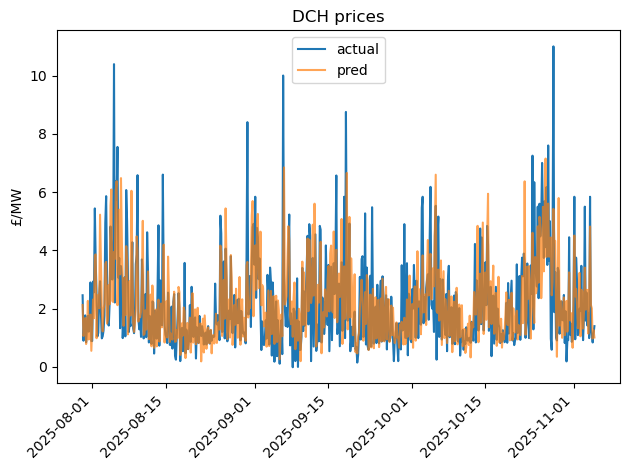

(1.2511657729707748, 1.8666831759235738, 39.54037879384384)


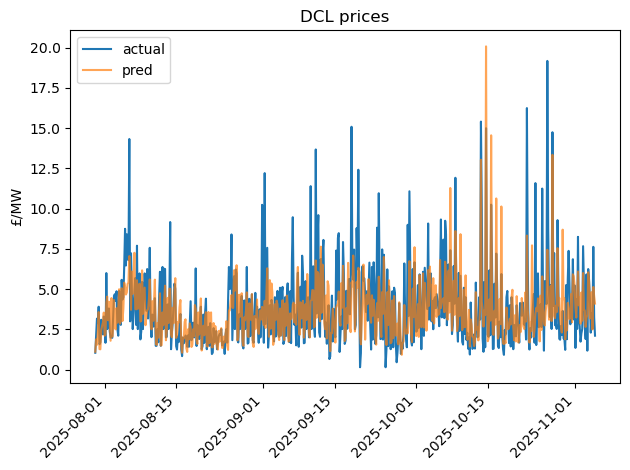

(1.2647216563379977, 1.7214593567407952, inf)


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_22024\3228516424.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


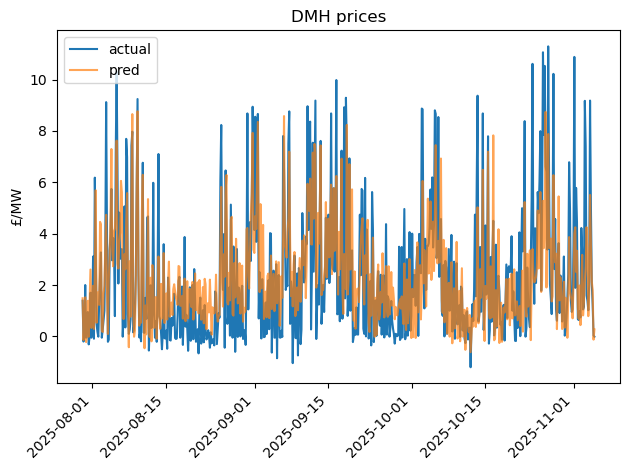

(1.6876115652727228, 2.298394178259727, 27.731112486504383)


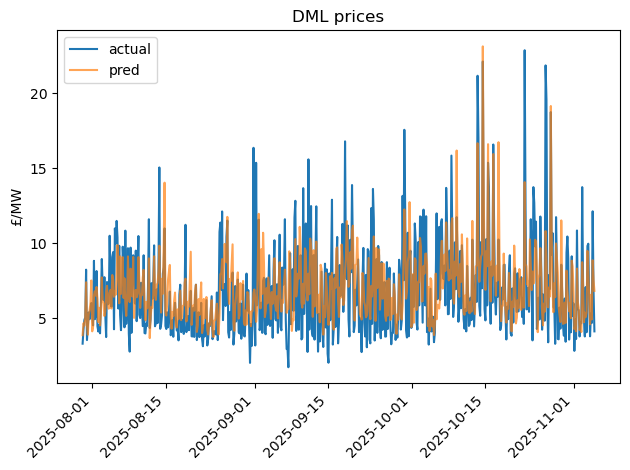

(1.85238722860511, 2.656242711136635, 96.21029362476101)


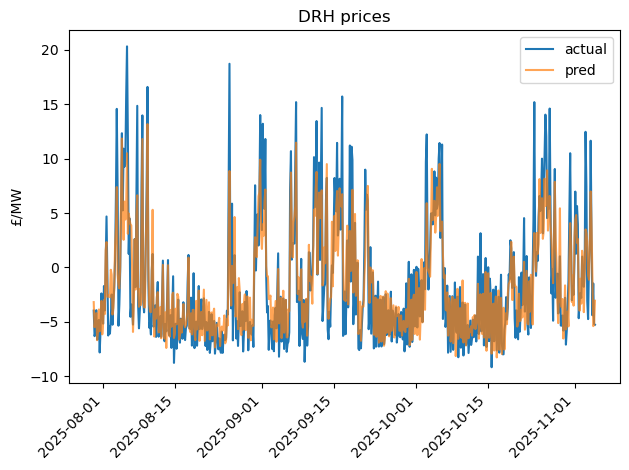

(3.5295377456768726, 4.949971795236778, 25.943822247263977)


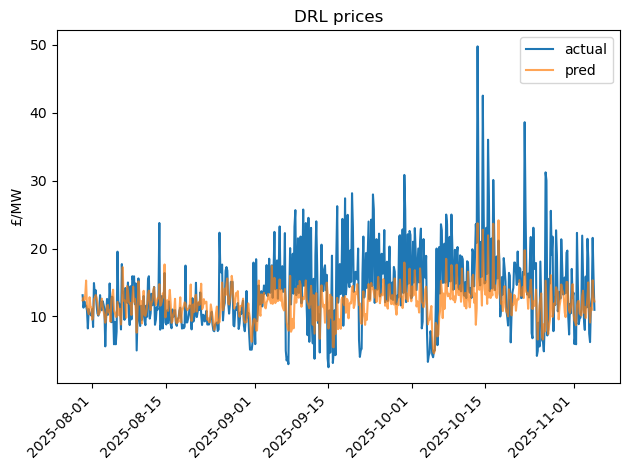

In [60]:
pred_test = pd.DataFrame(data = pred_test, index = test_panel.index)


mae_t, rmse_t, mape_t = eval_forecast(test_panel['hourly_price'].values,  pred_test.values)

print("Test       - MAE:", mae_t, "RMSE:", rmse_t, "MAPE:", mape_t)

actual = test_panel["hourly_price"]   # Series with MultiIndex
pred = pred_test                      # from res.predict(...)

for prod in actual.index.get_level_values("auctionProduct").unique():
    a = actual.xs(prod, level="auctionProduct")

    p = pred.xs(prod, level="auctionProduct")
    # make p 1D
    if isinstance(p, pd.DataFrame):
        p = p.iloc[:, 0]
    else:
        p = pd.Series(p).squeeze()

    df_plot = pd.concat([a.rename("actual"), p.rename("pred")], axis=1)
    
    print(eval_forecast(a.values, p.values))

    plt.figure()
    plt.plot(df_plot.index, df_plot["actual"], label="actual")
    plt.plot(df_plot.index, df_plot["pred"], label="pred", alpha=0.7)  
    plt.ylabel('£/MW')
    plt.xticks(rotation=45, ha="right")

    plt.title(f'{prod} prices')
    plt.legend()
    plt.tight_layout()
    
    plt.show()

## Flex value plotting

In [39]:
# nb_rows = (test.index.year == 2025).sum()
factor = 0.6

ev_cap = (((7.4 * 4) * 1689) ) * factor  # 1268
bess_cap = ((12 * 262) ) * factor #183
#hp 521 645
# elec storage heater (3.5*4)* 
pv_cap = (((5*4) * 1724) ) * factor



In [40]:
test_panel["sum_requested_mw"].clip(upper = ev_cap).values

array([1198., 1122., 1142., ...,  480.,  480.,  480.], shape=(3528,))

DCH 1548285.55
DCH deliveryStart
2025-07-31     21509.57
2025-08-31    507843.78
2025-09-30    447177.89
2025-10-31    508135.54
2025-11-30     63618.77
Freq: ME, dtype: float64


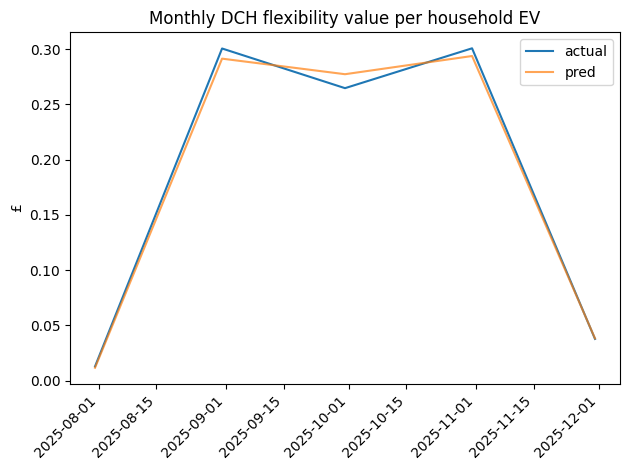

DCL 2874305.77
DCL deliveryStart
2025-07-31     36343.13
2025-08-31    809732.04
2025-09-30    950710.46
2025-10-31    950365.52
2025-11-30    127154.62
Freq: ME, dtype: float64


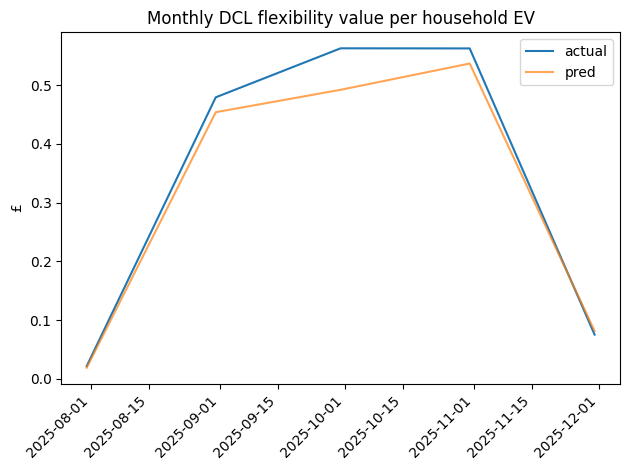

DMH 600613.0399999999
DMH deliveryStart
2025-07-31      2048.45
2025-08-31    119728.93
2025-09-30    172386.39
2025-10-31    267421.62
2025-11-30     39027.65
Freq: ME, dtype: float64


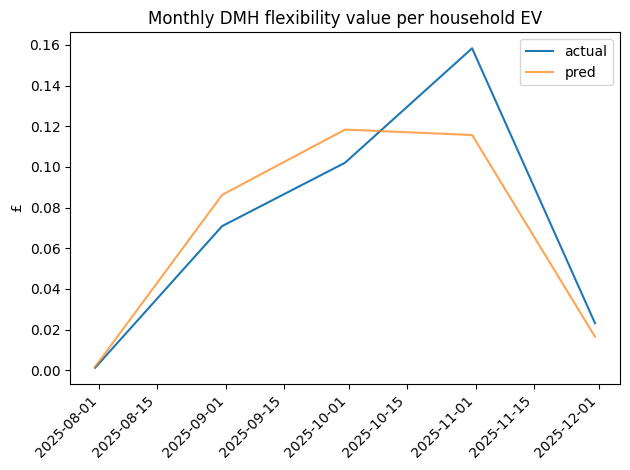

DML 1722575.93
DML deliveryStart
2025-07-31     18276.00
2025-08-31    404901.76
2025-09-30    497335.48
2025-10-31    724778.24
2025-11-30     77284.45
Freq: ME, dtype: float64


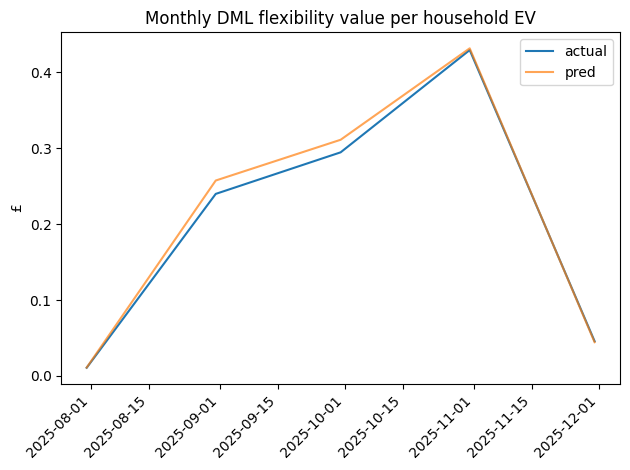

DRH -513574.61
DRH deliveryStart
2025-07-31    -31500.00
2025-08-31   -222283.72
2025-09-30   -142030.12
2025-10-31   -124689.02
2025-11-30      6928.25
Freq: ME, dtype: float64


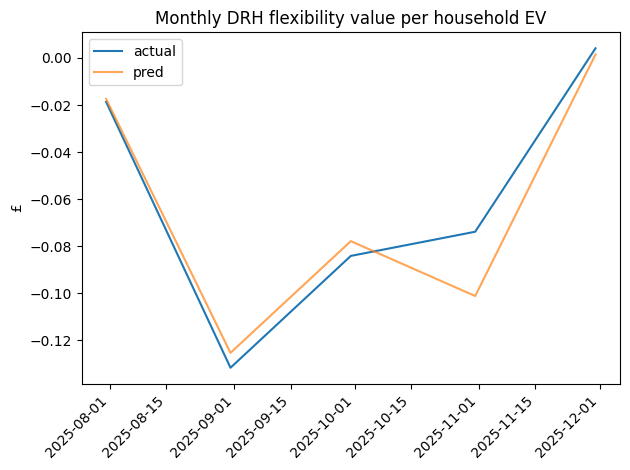

DRL 3945822.89
DRL deliveryStart
2025-07-31      63293.98
2025-08-31     981843.83
2025-09-30    1325237.70
2025-10-31    1429335.38
2025-11-30     146112.00
Freq: ME, dtype: float64


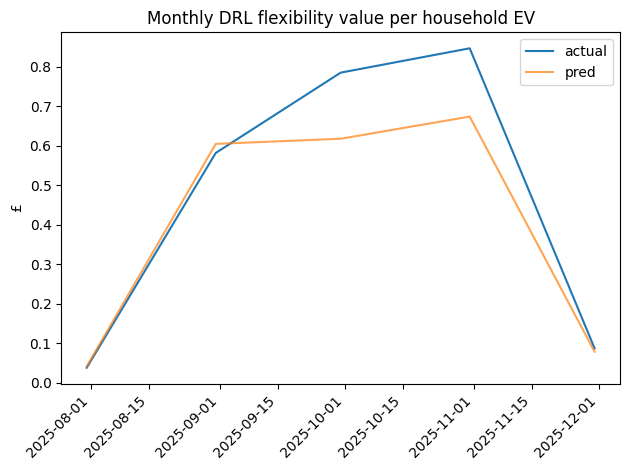

DCH 1548285.55
DCH deliveryStart
2025-07-31     21509.57
2025-08-31    507843.78
2025-09-30    447177.89
2025-10-31    508135.54
2025-11-30     63618.77
Freq: ME, dtype: float64


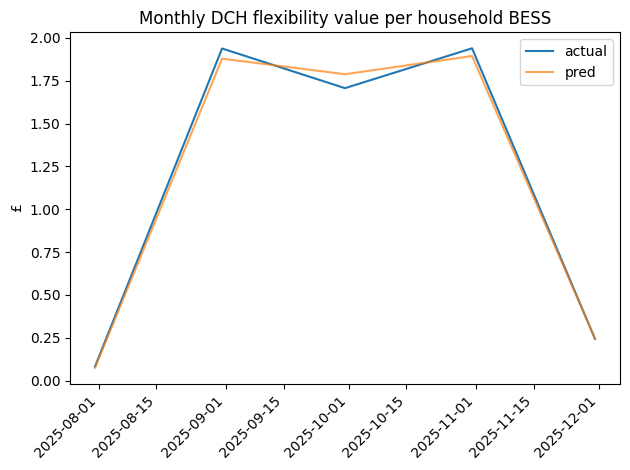

DCL 2874305.77
DCL deliveryStart
2025-07-31     36343.13
2025-08-31    809732.04
2025-09-30    950710.46
2025-10-31    950365.52
2025-11-30    127154.62
Freq: ME, dtype: float64


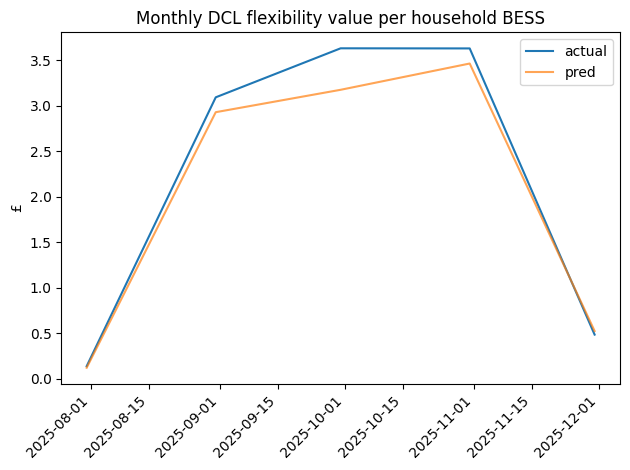

DMH 600613.0399999999
DMH deliveryStart
2025-07-31      2048.45
2025-08-31    119728.93
2025-09-30    172386.39
2025-10-31    267421.62
2025-11-30     39027.65
Freq: ME, dtype: float64


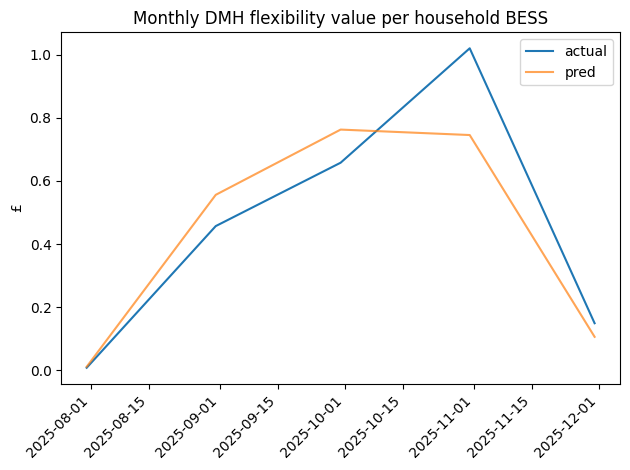

DML 1722575.93
DML deliveryStart
2025-07-31     18276.00
2025-08-31    404901.76
2025-09-30    497335.48
2025-10-31    724778.24
2025-11-30     77284.45
Freq: ME, dtype: float64


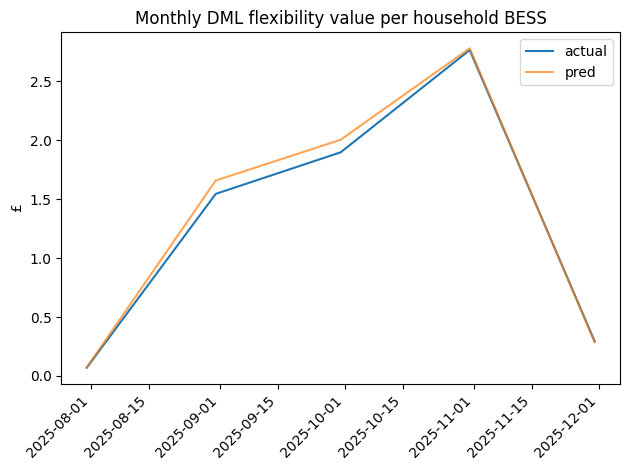

DRH -513574.61
DRH deliveryStart
2025-07-31    -31500.00
2025-08-31   -222283.72
2025-09-30   -142030.12
2025-10-31   -124689.02
2025-11-30      6928.25
Freq: ME, dtype: float64


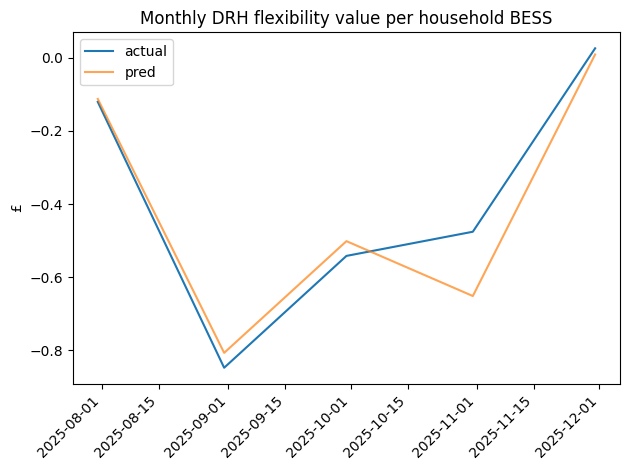

DRL 3945822.89
DRL deliveryStart
2025-07-31      63293.98
2025-08-31     981843.83
2025-09-30    1325237.70
2025-10-31    1429335.38
2025-11-30     146112.00
Freq: ME, dtype: float64


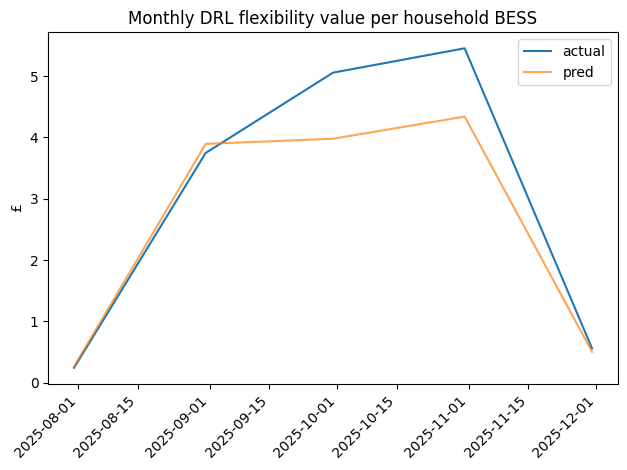

In [41]:
for label, cap, nb in zip(['EV', 'BESS'], [ev_cap, bess_cap], [1689000,262000]):
    
    actual = test_panel["hourly_price"] * test_panel["sum_requested_mw"].clip(upper = cap)   # Series with MultiIndex
    pred = pd.DataFrame(data = pred_test * test_panel["sum_requested_mw"].clip(upper = cap).values, index = test_panel.index)
    
    

    for prod in actual.index.get_level_values("auctionProduct").unique():
        a = actual.xs(prod, level="auctionProduct")

        p = pred.xs(prod, level="auctionProduct")
        # make p 1D
        if isinstance(p, pd.DataFrame):
            p = p.iloc[:, 0]
        else:
            p = pd.Series(p).squeeze()

        df_plot = pd.concat([a.rename("actual"), p.rename("pred")], axis=1)
        print(prod, a.sum())
        print(prod, a.resample('ME').sum())
        
        plt.figure()
        plt.plot(df_plot.resample('ME').sum().index, df_plot["actual"].resample('ME').sum()/nb, label="actual")
        plt.plot(df_plot.resample('ME').sum().index, df_plot["pred"].resample('ME').sum()/nb, label="pred", alpha=0.7)  
        plt.ylabel('£')
        plt.xticks(rotation=45, ha="right")

        plt.title(f'Monthly {prod} flexibility value per household {label}')
        plt.legend()
        plt.tight_layout()
        
        plt.show()

In [ ]:
for label, cap in zip(['EVs', 'BESS'], [ev_cap, bess_cap]):
    
    actual = test_panel["hourly_price"] * test_panel["sum_requested_mw"].clip(upper = cap)   # Series with MultiIndex
    pred = pd.DataFrame(data = pred_test * test_panel["sum_requested_mw"].clip(upper = cap).values, index = test_panel.index)


    for prod in actual.index.get_level_values("auctionProduct").unique():
        a = actual.xs(prod, level="auctionProduct")

        p = pred.xs(prod, level="auctionProduct")
        # make p 1D
        if isinstance(p, pd.DataFrame):
            p = p.iloc[:, 0]
        else:
            p = pd.Series(p).squeeze()

        df_plot = pd.concat([a.rename("actual"), p.rename("pred")], axis=1)
        
        print(eval_forecast(a.values, p.values))

        plt.figure()
        plt.plot(df_plot.index, df_plot["actual"], label="actual")
        plt.plot(df_plot.index, df_plot["pred"], label="pred", alpha=0.7)  
        plt.ylabel('£')
        plt.xticks(rotation=45, ha="right")

        plt.title(f'{prod} flexibility value for {label}')
        plt.legend()
        plt.tight_layout()
        
        plt.show()

DCH 22.917681599999998
DCL 40.723679999999995
DMH 24.584279999999996
DML 71.1058896
DRH -17.136446399999997
DRL 146.3452416
DCH 9.290952
DCL 16.5096
DMH 9.966600000000001
DML 28.826712
DRH -6.947208
DRL 59.32915200000001


In [ ]:
#                   
# no of assets
# Total asset size in mw
# value over test period
# value per asset per month

C:\Users\Duval1e\AppData\Local\Temp\ipykernel_22024\3228516424.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


(1021.199339722966, 1508.3582799778806, inf)


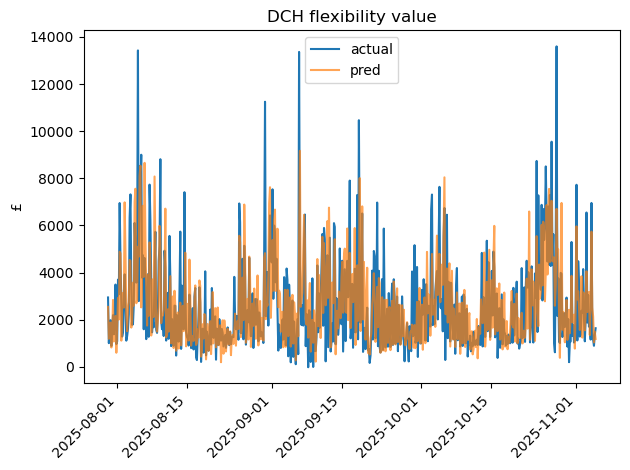

(1568.6929554561564, 2354.4118036442787, 39.540378793843836)


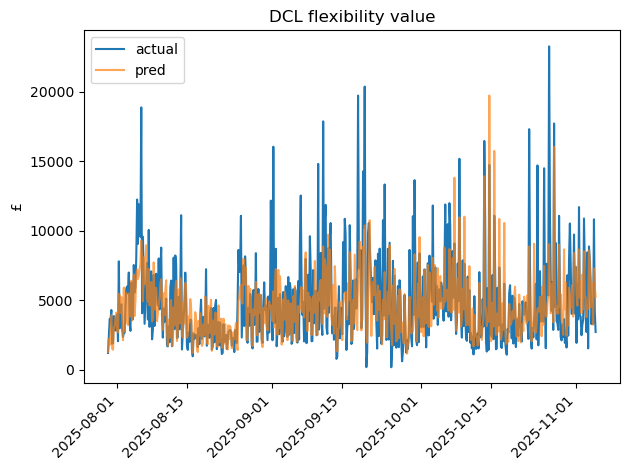

(557.6852647957131, 782.5763456773434, inf)


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_22024\3228516424.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


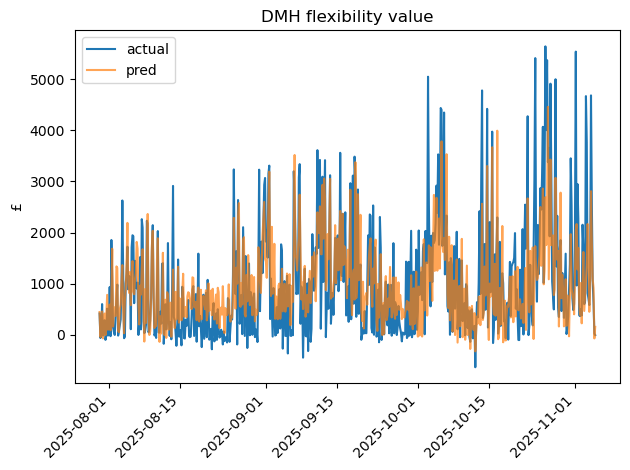

(722.4400417530197, 998.9278924549989, 27.73111248650439)


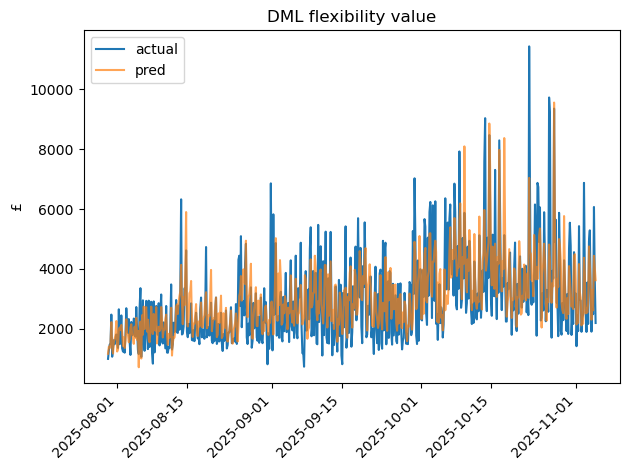

(901.3490243289083, 1275.6156686879137, 96.21029362476101)


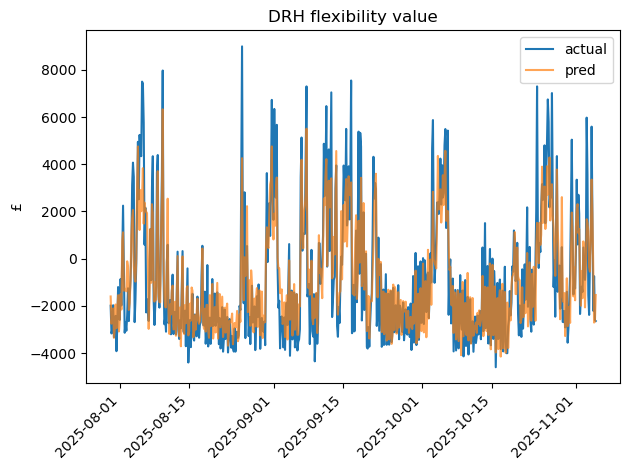

(1691.6883391083752, 2374.7123053192786, 25.943822247263977)


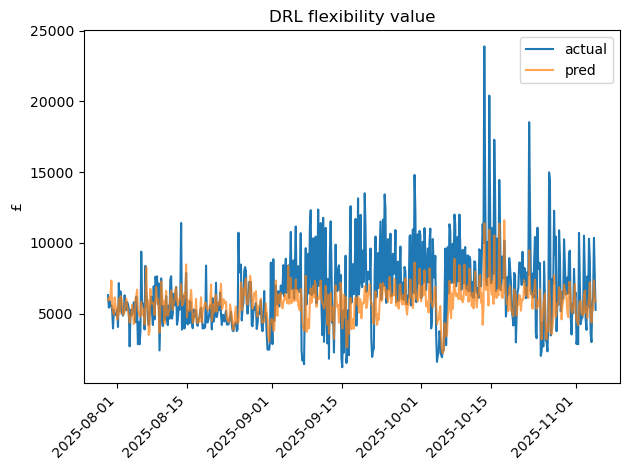

In [59]:
actual = test_panel["hourly_price"] * test_panel["sum_requested_mw"]   # Series with MultiIndex
pred = pd.DataFrame(data = pred_test * test_panel["sum_requested_mw"].values, index = test_panel.index)


for prod in actual.index.get_level_values("auctionProduct").unique():
    a = actual.xs(prod, level="auctionProduct")

    p = pred.xs(prod, level="auctionProduct")
    # make p 1D
    if isinstance(p, pd.DataFrame):
        p = p.iloc[:, 0]
    else:
        p = pd.Series(p).squeeze()

    df_plot = pd.concat([a.rename("actual"), p.rename("pred")], axis=1)
    
    print(eval_forecast(a.values, p.values))

    plt.figure()
    plt.plot(df_plot.index, df_plot["actual"], label="actual")
    plt.plot(df_plot.index, df_plot["pred"], label="pred", alpha=0.7)  
    plt.ylabel('£')
    plt.xticks(rotation=45, ha="right")

    plt.title(f'{prod} flexibility value')
    plt.legend()
    plt.tight_layout()
    
    plt.show()

## evaluation

In [311]:
pred_test  = model.predict(X_test)

# pred_val.index = valid.index
pred_test = pd.DataFrame(data = pred_test, index = test_panel.index)

In [312]:
# mae_v, rmse_v, mape_v = eval_forecast(valid['hourly_price'][pred_val.index.notna()], pred_val.dropna())

mae_t, rmse_t, mape_t = eval_forecast(test_panel['hourly_price'].values,  pred_test.values)

print("Test       - MAE:", mae_t, "RMSE:", rmse_t, "MAPE:", mape_t)


Test       - MAE: 1.9745731368587958 RMSE: 2.9654614292550776 MAPE: inf


C:\Users\Duval1e\AppData\Local\Temp\ipykernel_24088\338728343.py:4: RuntimeWarning: divide by zero encountered in divide
  mape = (np.abs((actual - pred) / actual)).mean() * 100


In [ ]:
# NOT linear regression because assumes price moves smoothly with MW 
# --> SATURATION/THERSHOLDING : clearing price is driven by the marginal (highest-priced) executed sell order—so volumes can change without moving price until you cross into a new tranche.
# will to treat data in bins TBD

# PANEL REGRESSION : Multiple markets over time

# FIXED EFFECTS MODEL : because products (DC/DM/DR) might have different typical price levels even when volumes and tightness are the same.
## add vraibles for hour, day of the week vs weekend, season
# DYNAMIC with lagged features (Prices don’t jump randomly every 30 minutes; they tend to move gradually)

# We need INTERACTION variables: the effect of MW on price isn’t constant — it depends on another variable, like how “tight” the system is.
# When the system is loose (lots of headroom), increasing required MW by +5 might barely move the clearing price and vice versa
# Intercation terms must be SCALED for interpretability of coefs
# add market to interaction because each market diff ??? (maybe DC reacts more strongly to tightness than DR)

## EVALUATION
# Absolute measure

#######################

# df['hh'] = df.index.hour * 2 + (df.index.minute // 30)   # 0..47
# df['dow'] = df.index.dayofweek                          # 0=Mon..6=Sun

# # Log prices
# df['log_price']        = np.log(df['market_price'])
# df['log_system_price'] = np.log(df['system_price'])

# # ---- LAGS: VERY IMPORTANT → do per market ----
# df['log_price_lag1']  = df.groupby('market')['log_price'].shift(1)
# df['log_price_lag48'] = df.groupby('market')['log_price'].shift(48)

# # Drop rows where lags are missing
# df = df.dropna()